In [110]:
%matplotlib inline

from collections import OrderedDict
from importlib import reload
import os, sys

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm

import numpy as np
import pandas as pd
import scipy.stats

from astropy.table import Table, vstack
from astropy.stats import mad_std
from astropy.constants import iau2012 as const

from scipy.stats import spearmanr, gaussian_kde
import statsmodels.api as sm

from astropy.table import QTable
import cdspyreadme

import seaborn as sns

sys.path.append('../aklpyutils/')
sys.path.append('../')
from utils_stats import *

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import MaxNLocator
from shapely.geometry import Point
from shapely.ops import cascaded_union

from jsplottools.sun_plot_tools.general import mpl_setup
from jsplottools.sun_plot_tools.ax import *
from jsplottools.sun_plot_tools.fig import *
mpl_setup(figtype='paper-1/3')
params = {'legend.fontsize': 'x-large',          
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
plt.rcParams.update(params)

from astropy.io import ascii
import glob, os

from matplotlib.patches import FancyArrowPatch

In [111]:
# import importlib
# importlib.reload(key_dirs)

# from key_dirs import *
# from utils_spacing import *

def get_source_list(folder):
    temp_source_list = os.listdir(folder)
    temp_source_list.sort()
    source_list = []
    for this_source_file in temp_source_list:
        this_source = this_source_file.split('_')[0]
        source_list.append(this_source)
        source_array = np.unique(np.array(source_list))

    return source_array

def agregt_bins_ppac(cross_dict, source_list, tpcf_tag='realvsflat', unc_method='error propagation'):
    source_exmp = list(cross_dict.keys())[0]
    bins_xgeo = cross_dict[source_exmp][tpcf_tag]['xmid']
    nbins = len(bins_xgeo)
    corr_agg_16 = np.zeros_like(bins_xgeo)*np.nan
    corr_agg_50 = np.zeros_like(bins_xgeo)*np.nan
    corr_agg_84 = np.zeros_like(bins_xgeo)*np.nan
    corr_agg_errlo = np.zeros_like(bins_xgeo)*np.nan
    corr_agg_errhi = np.zeros_like(bins_xgeo)*np.nan

    for ii in range(nbins):

        # Extract vectors for this bin
        corr_bin_list = []

        for this_source in source_list:
            this_entry = cross_dict[this_source]
            # real_coeff = np.array(this_entry['real']['ymean'])[ii] / np.nanmax(this_entry['real']['ymean'])
            # model_coeff = np.array(this_entry['model']['ymean'])[ii] / np.nanmax(this_entry['model']['ymean'])
            corr_bin_list.append(np.array(this_entry[tpcf_tag]['twopt'])[ii])


        corr_bin_arr = np.array(corr_bin_list)

        # Caclulate perecentiles and save results
        vec = corr_bin_arr[np.where(~np.isnan(corr_bin_arr))]
        corr_agg_16[ii] = np.nanpercentile(vec,16)
        corr_agg_50[ii] = np.nanpercentile(vec,50)
        corr_agg_84[ii] = np.nanpercentile(vec,84)

        n_fin = np.sum(np.isfinite(vec))
        # calculate the uncertainty of the median
        if unc_method == 'error propagation':
            corr_agg_errlo[ii] = \
                1.253 * (np.nanpercentile(vec,50) - np.nanpercentile(vec,16))/np.sqrt(n_fin)
            corr_agg_errhi [ii]= \
                1.253 * (np.nanpercentile(vec,84) - np.nanpercentile(vec,50))/np.sqrt(n_fin)
        elif unc_method == 'bootstrap':
            n_bootstrap = 1000
            medians = np.array([])
            for _ in range(n_bootstrap):
                sample = np.random.choice(vec, size=n_fin, replace=True)
                medians = np.append(medians, np.median(sample))
            corr_agg_errlo[ii] = corr_agg_errhi[ii] =  np.std(medians)
        
    return bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi

In [112]:
nthresh = 50
# corr_dir = '../corr_lo_150pc_results/'
corr_dir = '../corr_results_deproj/'
fid_cat_dir = '../cloud_cats_fits/homogen_lo_150pc_props/'
fid_cat_dir = '../cloud_cats_fits/homogen_hi_150pc_props/'

source_list = get_source_list(corr_dir)

# Sample table
sample_tab_file = '../phangs_sample_table_v1p6.fits'
sample_tab = Table.read(sample_tab_file)
sample_tab['name'][0] = 'circinus'

fid_cat_dict = {} 
fid_cov_dict = {}
fid_ncloud_dict = {}
fid_ncloud_list = []

array_dict = {}
deets_dict = {}
mom0_map_dict = {} 
broad_map_dict = {}

for this_source in source_list:

    sample_tab_row = int(np.where(sample_tab['name'] == this_source)[0])
    deets_dict[this_source] = sample_tab[sample_tab_row]

    fidcat_glob = glob.glob(fid_cat_dir+this_source+'*_props.fits')
    if len(fidcat_glob) != 1:
        print("Unexpected number of catalogs: ", fidcat_glob)
        print("... for ", this_source)
    fid_cat_dict[this_source] = fidcat_glob[0]

    cloud_cat = Table.read(fidcat_glob[0], format='fits')
    nclouds = len(cloud_cat)
    fid_ncloud_list.append(nclouds)
    fid_ncloud_dict[this_source] = nclouds

**Load the Correlation Functions**

In [113]:
# get the weird sources based on the flux recovery fraction
gal_propt = ascii.read('../Leroy_PHANGS_galaxies.txt')
for i, name in enumerate(gal_propt['Galaxy']):
    gal_propt['Galaxy'][i] = (gal_propt['Galaxy'][i].lower()).replace(" ", "")

index_map = {name: idx for idx, name in enumerate(sample_tab['name'])}
new_order_indices = [index_map[name] for name in gal_propt['Galaxy'] if name in index_map.keys()]

if 'f_recvr' not in sample_tab.columns:
    sample_tab.add_column(np.nan, name='f_recvr')
if 'faint_lab' not in sample_tab.columns:
    sample_tab.add_column(' ', name='faint_lab')
for i in range(len(gal_propt)):
    sample_tab['f_recvr'][new_order_indices[i]] = gal_propt['Comp2'][i]
    sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]

sample_tab[['f_recvr', 'faint_lab']]

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/136037524.py:15: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/136037524.py:15: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/136037524.py:15: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/136037524.py:15: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/136037524.py:15: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/136037524.py:15: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/136037524.py:15: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/136037524.py:15: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_

f_recvr,faint_lab
float64,str1
77.7,0
nan,
nan,
70.7,0
nan,
56.1,0
7.1,F
nan,
7.2,0


In [114]:
corr_dict = {}
first = True

source_nthresh = ['ngc0300','ngc3489','ngc4459', 'ngc4476', 'ngc4477', 'ngc4596', 'ngc4731', 'ngc4826', 'ngc7456', 'ngc7793']
source_bin = [source for source in source_list if source not in source_nthresh]

for this_source in source_list:
    
    # Load files
    
    expvsflat_file = corr_dir + this_source+'_expvsflat.fits'
    realvsflat_file = corr_dir + this_source+'_realvsflat.fits'
    realvsexp_file = corr_dir + this_source+'_realvsexp.fits'
    realvsrad_file = corr_dir + this_source+'_realvsrad.fits'
    realvsIco_file = corr_dir + this_source+'_realvsIco.fits'
    
    if os.path.isfile(realvsflat_file) == False:        
        print(this_source, " missing a correlation file.")
        continue     
    
    realvsexp_tab = Table.read(realvsexp_file)
    realvsflat_tab = Table.read(realvsflat_file)
    # expvsflat_tab = Table.read(expvsflat_file)
    realvsrad_tab = Table.read(realvsrad_file)
    realvsIco_tab = Table.read(realvsIco_file)
    
    fidlogx = 2.7
    
    templogx = np.log10(realvsflat_tab['xgeo'])
    templogy = np.log10(realvsflat_tab['twopt'])
    mask = np.full(np.shape(templogy), fill_value=True)
    try:
        mask = (mask & (~templogy.mask))
    except:
        mask = mask
    realvsflat_atfid = np.interp(fidlogx,templogx[np.where(mask)],templogy[np.where(mask)],left=np.nan,right=np.nan)
    peaklogx_flat = templogx[12:21][np.nanargmax(templogy[12:21])]
    peaklogy_flat = np.nanmax(templogy[12:21])

    templogx = np.log10(realvsexp_tab['xgeo'])
    templogy = np.log10(realvsexp_tab['twopt'])
    mask = np.full(np.shape(templogy), fill_value=True)
    try:
        mask = (mask & (~templogy.mask))
    except:
        mask = mask
    realvsexp_atfid = np.interp(fidlogx,templogx[np.where(mask)],templogy[np.where(mask)],left=np.nan,right=np.nan)
    peaklogx_exp = templogx[12:21][np.nanargmax(templogy[12:21])]
    peaklogy_exp = np.nanmax(templogy[12:21])

    # templogx = np.log10(expvsflat_tab['xgeo'])
    # templogy = np.log10(expvsflat_tab['twopt'])
    # mask = np.full(np.shape(templogy), fill_value=True)
    # try:
    #     mask = (mask & (~templogy.mask))
    # except:
    #     mask = mask
    # expvsflat_atfid = np.interp(fidlogx,templogx[np.where(mask)],templogy[np.where(mask)],left=np.nan,right=np.nan)

    templogx = np.log10(realvsrad_tab['xgeo'])
    templogy = np.log10(realvsrad_tab['twopt'])
    mask = np.full(np.shape(templogy), fill_value=True)
    try:
        mask = (mask & (~templogy.mask))
    except:
        mask = mask
    realvsrad_atfid = np.interp(fidlogx,templogx[np.where(mask)],templogy[np.where(mask)],left=np.nan,right=np.nan)
    peaklogx_rad = templogx[12:21][np.nanargmax(templogy[12:21])]
    peaklogy_rad = np.nanmax(templogy[12:21])

    templogx = np.log10(realvsIco_tab['xgeo'])
    templogy = np.log10(realvsIco_tab['twopt'])
    mask = np.full(np.shape(templogy), fill_value=True)
    try:
        mask = (mask & (~templogy.mask))
    except:
        mask = mask
    realvsIco_atfid = np.interp(fidlogx,templogx[np.where(mask)],templogy[np.where(mask)],left=np.nan,right=np.nan)
    peaklogx_Ico = templogx[12:21][np.nanargmax(templogy[12:21])]
    peaklogy_Ico = np.nanmax(templogy[12:21])

    fid_cat = Table.read(fid_cat_dict[this_source].replace('_props.fits','_props_valueadded.fits'))
    max_rad_deg = np.nanmax(np.sqrt(fid_cat['DELTAX_DEG']**2+fid_cat['DELTAY_DEG']**2))
    
    # Store some arrays if first one
    if first:        
        bins_xlo = np.array(realvsflat_tab['xlo'])
        bins_xhi = np.array(realvsflat_tab['xhi'])
        bins_xgeo = np.array(realvsflat_tab['xgeo'])
        bins_xmid = np.array(realvsflat_tab['xmid'])
        nbins = len(bins_xgeo)        
        first=False
    
    corr_dict[this_source] = {
        'galaxy': this_source.upper(), 
        'nclouds':len(fid_cat),
        'max_rad_deg':max_rad_deg,
        'fidlogx':fidlogx,
        'realvsexp':realvsexp_tab,
        'realvsexp_atfid':realvsexp_atfid,
        'realvsexp_logx_max': peaklogx_exp, 
        'realvsexp_max': peaklogy_exp, 
        'realvsflat':realvsflat_tab,
        'realvsflat_atfid':realvsflat_atfid,
        'realvsflat_logx_max': peaklogx_flat, 
        'realvsflat_max':peaklogy_flat,
        # 'expvsflat':expvsflat_tab,
        # 'expvsflat_atfid':expvsflat_atfid,
        'realvsrad':realvsrad_tab,
        'realvsrad_atfid':realvsrad_atfid, 
        'realvsrad_logx_max': peaklogx_rad, 
        'realvsrad_max':peaklogy_rad,
        'realvsIco':realvsIco_tab,
        'realvsIco_atfid':realvsIco_atfid, 
        'realvsIco_logx_max': peaklogx_Ico, 
        'realvsIco_max':peaklogy_Ico,
    }
    
    #print(this_source, corr_dict[this_source]['nclouds'])

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/473141106.py:41: RuntimeWarning: invalid value encountered in log10
  templogy = np.log10(realvsexp_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/473141106.py:61: RuntimeWarning: invalid value encountered in log10
  templogy = np.log10(realvsrad_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/473141106.py:72: RuntimeWarning: invalid value encountered in log10
  templogy = np.log10(realvsIco_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/473141106.py:30: RuntimeWarning: invalid value encountered in log10
  templogy = np.log10(realvsflat_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/473141106.py:61: RuntimeWarning: divide by zero encountered in log10
  templogy = np.log10(realvsrad_tab['twopt'])


Put the dictionary into a table

In [115]:
columns_selct = ['galaxy', 'realvsflat_atfid', 'realvsexp_atfid', 'realvsrad_atfid', 'realvsIco_atfid', 
                 'realvsflat_logx_max', 'realvsexp_logx_max', 'realvsrad_logx_max', 'realvsIco_logx_max', 
                 'realvsflat_max', 'realvsexp_max', 'realvsrad_max', 'realvsIco_max'] 
stats_tab = Table()
for source in source_list:
    corr_dict_sub = {k:[corr_dict[source][k]] for k in columns_selct}
    tab_temp = Table(corr_dict_sub)
    stats_tab = vstack([stats_tab, tab_temp])

stats_tab = stats_tab[columns_selct]
columns_selct.remove('galaxy')

for column in columns_selct:
    stats_tab[column] = np.round(stats_tab[column], 2)
    
stats_tab["galaxy"] = stats_tab["galaxy"].astype("<U8")
for this_source in source_nthresh:
    idx = np.where(stats_tab['galaxy']==this_source.upper())
    stats_tab['galaxy'][idx] = this_source.upper()+'*'

latex_code = stats_tab.write(filename='../tables/table2.tex', format='latex', overwrite=True)

display(stats_tab)

stats_tab.write('../tables/tpcf_tab_unsort.fits', format='fits', overwrite=True)

galaxy,realvsflat_atfid,realvsexp_atfid,realvsrad_atfid,realvsIco_atfid,realvsflat_logx_max,realvsexp_logx_max,realvsrad_logx_max,realvsIco_logx_max,realvsflat_max,realvsexp_max,realvsrad_max,realvsIco_max
str8,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
IC1954,0.44,-0.02,-0.01,-0.03,2.35,2.35,2.35,2.35,0.6,0.15,0.13,0.08
IC5273,0.5,0.15,0.19,0.1,2.75,2.75,2.75,2.75,0.55,0.18,0.22,0.15
NGC0253,0.42,0.08,0.22,0.2,2.25,2.25,2.85,2.25,0.63,0.27,0.23,0.21
NGC0300*,0.48,-0.15,-0.47,0.29,2.55,2.55,2.55,2.55,0.93,0.53,0.52,0.55
NGC0628,0.07,0.06,0.04,0.0,2.45,2.45,2.45,2.45,0.22,0.18,0.16,0.12
NGC0685,0.22,-0.04,-0.01,-0.14,2.55,2.55,2.55,2.55,0.5,0.29,0.25,0.13
NGC1097,0.43,0.24,0.22,0.2,2.55,2.55,2.55,2.55,0.46,0.27,0.22,0.2
NGC1511,0.71,0.23,0.18,0.09,2.25,2.25,2.25,2.65,0.74,0.25,0.19,0.09
NGC1546,0.69,0.02,-0.01,-0.01,2.45,2.45,2.45,2.45,0.81,0.24,0.08,0.1


Put the result two point correlation function into a machine readable table

In [116]:
tpcf_full_tab = Table()
for source in source_list:
    if source in source_nthresh:
        source_name = source.upper()+'*'
    else:
        source_name = source.upper()
    tpcf_one_gal = Table()
    # input the galaxy name
    tpcf_one_gal['Galaxy'] = [source_name] * len(corr_dict[source]['realvsflat'])
    # input the radius
    tpcf_one_gal['Dsep'] = np.log10(corr_dict[source]['realvsflat']['xgeo'])
    tpcf_one_gal['RealvsFlatMed'] = np.log10(corr_dict[source]['realvsflat']['twopt'])
    tpcf_one_gal['RealvsFlatLo'] = np.log10(corr_dict[source]['realvsflat']['twopt']-corr_dict[source]['realvsflat']['twopt_err'])
    tpcf_one_gal['RealvsFlatUp'] = np.log10(corr_dict[source]['realvsflat']['twopt']+corr_dict[source]['realvsflat']['twopt_err'])
    # exponential disk
    tpcf_one_gal['RealvsExpMed'] = np.log10(corr_dict[source]['realvsexp']['twopt'])
    tpcf_one_gal['RealvsExpLo'] = np.log10(corr_dict[source]['realvsexp']['twopt']-corr_dict[source]['realvsexp']['twopt_err'])
    tpcf_one_gal['RealvsExpUp'] = np.log10(corr_dict[source]['realvsexp']['twopt']+corr_dict[source]['realvsexp']['twopt_err'])
    # CO radial profile
    tpcf_one_gal['RealvsRadMed'] = np.log10(corr_dict[source]['realvsrad']['twopt'])
    tpcf_one_gal['RealvsRadLo'] = np.log10(corr_dict[source]['realvsrad']['twopt']-corr_dict[source]['realvsrad']['twopt_err'])
    tpcf_one_gal['RealvsRadUp'] = np.log10(corr_dict[source]['realvsrad']['twopt']+corr_dict[source]['realvsrad']['twopt_err'])
    # Ico profile
    tpcf_one_gal['RealvsIcoMed'] = np.log10(corr_dict[source]['realvsIco']['twopt'])
    tpcf_one_gal['RealvsIcoLo'] = np.log10(corr_dict[source]['realvsIco']['twopt']-corr_dict[source]['realvsIco']['twopt_err'])
    tpcf_one_gal['RealvsIcoUp'] = np.log10(corr_dict[source]['realvsIco']['twopt']+corr_dict[source]['realvsIco']['twopt_err'])

    # stack the table
    tpcf_full_tab = vstack([tpcf_full_tab, tpcf_one_gal])

mask = (tpcf_full_tab['Dsep']>2.1) & (tpcf_full_tab['Dsep']<3.5)
tpcf_full_tab = tpcf_full_tab[mask]

# round the values to 2 digits
column_vals = ['Dsep', 'RealvsFlatMed', 'RealvsFlatLo', 'RealvsFlatUp', 'RealvsExpMed', 'RealvsExpLo', 'RealvsExpUp', 
                'RealvsRadMed', 'RealvsRadLo', 'RealvsRadUp', 'RealvsIcoMed', 'RealvsIcoLo', 'RealvsIcoUp']

tpcf_full_tab_tex = tpcf_full_tab.copy()
for col in column_vals:
    tpcf_full_tab_tex[col] = np.round(tpcf_full_tab[col], 2)

display(tpcf_full_tab_tex)

# write the table into a tex file
tpcf_full_tab_tex.write('../tables/tpcf_full_tab.tex', format='latex', overwrite=True)

# # write the table into a fits file
# tpcf_full_tab.write('../tables/tpcf_full_tab.fits', format='fits', overwrite=True)

# add description to the table column
tpcf_full_tab['Galaxy'].description = 'Galaxy name'
tpcf_full_tab['Dsep'].unit = "[pc]"
tpcf_full_tab['Dsep'].description = "The log10 value of the separation distance between giant molecular clouds"
tpcf_full_tab['RealvsFlatMed'].description = "The log10 value of the two point correlation amplitude with 'Flat' control"
tpcf_full_tab['RealvsFlatLo'].description = "The log10 value of the two correlation lower limit with 'Flat' control"
tpcf_full_tab['RealvsFlatUp'].description = "The log10 value of the two correlation upper limit with 'Flat' control"
tpcf_full_tab['RealvsExpMed'].description = "The log10 value of the two point correlation amplitude with 'Exp' control"
tpcf_full_tab['RealvsExpLo'].description = "The log10 value of the two correlation lower limit with 'Exp' control"
tpcf_full_tab['RealvsExpUp'].description = "The log10 value of the two correlation upper limit with 'Exp' control"
tpcf_full_tab['RealvsRadMed'].description = "The log10 value of the  two point correlation amplitude with 'Rad' control"
tpcf_full_tab['RealvsRadLo'].description = "The log10 value of the two correlation lower limit with 'Rad' control"
tpcf_full_tab['RealvsRadUp'].description = "The log10 value of the two correlation upper limit with 'Rad' control"
tpcf_full_tab['RealvsIcoMed'].description = "The log10 value of the two point correlation amplitude with 'Ico' control"
tpcf_full_tab['RealvsIcoLo'].description = "The log10 value of the two correlation lower limit with 'Ico' control"
tpcf_full_tab['RealvsIcoUp'].description = "The log10 value of the  two correlation upper limit with 'Ico' control"
# convert the table to the cds format

author_list = ["He, H.", "Leroy, A.K.", "Rosolowsky, E.", "Hughes, A.", "Sun, J.", "Machado, J.", "Bigiel, F.", "Barnes, A.", "Bazzi, Z.", "Cao, Y.", "Chevance, M.", "Colombo, D.", "Glover, S.C.O.",
    "Henshaw, J.D.", "Koch, E.W.", "Meidt, S.E.", "Pan, H.", "Saito, T.", "Sarbadhicary, S.K.", "Schinnerer, E.", "Smith, R.J.", "Usero, A.", "Weinberg, D.H.", "Williams, T.G."]

maker = cdspyreadme.CDSTablesMaker(outfolder='../tables/CDS/')
maker.catalogue = "PHANGS-ALMA GMC clustering"
maker.title = 'The structure of molecular gas in PHANGS-ALMA galaxies: cloud spacing, two-point correlation and stacked intensity profiles'
maker.author = "He et al. "
maker.date = 2026
for a in author_list:
    maker.add_author(a)
maker.bibcode = "2026A&A...accepted"

maker.abstract = ("We use two-point correlation function (2PCF) to characterize GMC spatial distribution across different spatial scales. When analyzing 2PCFs, we "
                 "generate several control samples that reflect different null hypotheses on large spatial scales. Once we accounted for the large-scale distribution, we find " 
                 "the peak excess clustering relative to the null hypotheses drops from 2.3 to 1.3, which suggests that galaxy structure exerts a strong influence on the GMC distribution "
                 "in galaxy disks. So far, this is the largest nearby galaxy sample with such study conducted. We provide readers the calculated 2PCF of individual galaxies using different "
                 "controls for future comparison. "
                    )       
maker.more_description = (
    "The table gives two-point correlation functions measured for "
    "individual PHANGS-ALMA galaxies using several choices of control/random "
    "catalogues."
)
maker.license = "CC-BY-4.0"
maker.keywords = ("ISM:structure; galaxies:ISM; galaxies:spiral; galaxies:structure")

cds_table = maker.addTable(tpcf_full_tab, name='table_b1.dat',
                           description='Two-point correlation functions of individual galaxies')

maker.writeCDSTables()
maker.makeReadMe()

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/975636467.py:13: RuntimeWarning: divide by zero encountered in log10
  tpcf_one_gal['RealvsFlatLo'] = np.log10(corr_dict[source]['realvsflat']['twopt']-corr_dict[source]['realvsflat']['twopt_err'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/975636467.py:13: RuntimeWarning: invalid value encountered in log10
  tpcf_one_gal['RealvsFlatLo'] = np.log10(corr_dict[source]['realvsflat']['twopt']-corr_dict[source]['realvsflat']['twopt_err'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/975636467.py:16: RuntimeWarning: invalid value encountered in log10
  tpcf_one_gal['RealvsExpMed'] = np.log10(corr_dict[source]['realvsexp']['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/975636467.py:17: RuntimeWarning: divide by zero encountered in log10
  tpcf_one_gal['RealvsExpLo'] = np.log10(corr_dict[source]['realvsexp']['twopt']-corr_dict[source]['realvsexp']['twopt_err'])

Galaxy,Dsep,RealvsFlatMed,RealvsFlatLo,RealvsFlatUp,RealvsExpMed,RealvsExpLo,RealvsExpUp,RealvsRadMed,RealvsRadLo,RealvsRadUp,RealvsIcoMed,RealvsIcoLo,RealvsIcoUp
str8,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
IC1954,2.15,0.46,-0.07,0.7,0.02,-0.51,0.25,-0.09,-0.62,0.14,-0.11,-0.64,0.13
IC1954,2.25,0.3,-0.23,0.53,-0.2,-0.73,0.03,-0.03,-0.56,0.21,-0.11,-0.64,0.12
IC1954,2.35,0.6,0.38,0.75,0.15,-0.08,0.3,0.13,-0.1,0.27,0.08,-0.14,0.23
IC1954,2.45,0.2,-0.1,0.37,-0.37,-0.67,-0.19,-0.25,-0.55,-0.07,-0.27,-0.57,-0.09
IC1954,2.55,0.37,0.19,0.49,-0.09,-0.27,0.03,-0.1,-0.27,0.03,-0.11,-0.28,0.02
IC1954,2.65,0.41,0.29,0.51,-0.08,-0.2,0.02,-0.02,-0.15,0.08,-0.05,-0.18,0.05
IC1954,2.75,0.46,0.37,0.53,0.03,-0.06,0.1,0.0,-0.09,0.08,-0.02,-0.11,0.06
IC1954,2.85,0.57,0.5,0.62,0.14,0.07,0.19,0.09,0.03,0.15,0.08,0.02,0.13
IC1954,2.95,0.42,0.36,0.47,-0.03,-0.09,0.02,-0.02,-0.08,0.03,-0.02,-0.08,0.03


Create moment maps sort by the fiducial amplitude

In [117]:
stats_tab.sort('realvsIco_atfid')
source_list_sort = stats_tab['galaxy']
source_list_sort = [source.replace('*', '') for source in source_list_sort]
stats_tab.write('../tables/tpcf_tab.fits', format='fits', overwrite=True)
print(stats_tab)

 galaxy  realvsflat_atfid realvsexp_atfid ... realvsrad_max realvsIco_max
-------- ---------------- --------------- ... ------------- -------------
NGC4596*             0.64            0.55 ...          0.47          0.76
NGC4731*             0.34            0.22 ...          0.68          0.26
NGC3489*             0.54            0.21 ...           0.4          0.42
 NGC0685             0.22           -0.04 ...          0.25          0.13
NGC4826*             0.52            0.14 ...          0.18          0.22
 NGC4781              0.5            0.04 ...          0.09          0.03
 NGC3137              0.5             0.1 ...          0.09          0.07
  IC1954             0.44           -0.02 ...          0.13          0.08
NGC4476*             1.17            0.72 ...          0.39          0.53
NGC7456*             0.53            0.32 ...          0.44          0.28
     ...              ...             ... ...           ...           ...
 NGC2903             0.23            0

#### Correlate the peak spacing with the median peak scale

**Load some galaxy properties**

In [118]:
source_list_ra = np.array(source_list)

mass_ra = np.zeros(len(source_list_ra))
lco_ra = np.zeros(len(source_list_ra))
sfr_ra = np.zeros(len(source_list_ra))
lstar_ra = np.zeros(len(source_list_ra))
incl_ra = np.zeros(len(source_list_ra))

ncloud_ra = np.zeros(len(source_list_ra))*np.nan
norm_realflat_ra = np.zeros(len(source_list_ra))*np.nan
norm_realexp_ra = np.zeros(len(source_list_ra))*np.nan
norm_expflat_ra = np.zeros(len(source_list_ra))*np.nan
norm_realrad_ra = np.zeros(len(source_list_ra))*np.nan
norm_realIco_ra = np.zeros(len(source_list_ra))*np.nan
max_rad_ra = np.zeros(len(source_list_ra))*np.nan

for ii, this_source in enumerate(source_list_ra):
    deets = deets_dict[this_source]
    mass_ra[ii] = float(deets['props_mstar'])
    sfr_ra[ii] = float(deets['props_sfr'])
    lco_ra[ii] = float(deets['lco_phangs'])
    incl_ra[ii] = float(deets['orient_incl'])
    deg_to_pc = float(np.pi/180.*deets['dist']*1e3)
    lstar_ra[ii] = float(deets['size_scalelength']/3600.*deg_to_pc)
    if this_source in corr_dict.keys():
        ncloud_ra[ii] = corr_dict[this_source]['nclouds']
        norm_realflat_ra[ii] = corr_dict[this_source]['realvsflat_atfid']
        norm_realexp_ra[ii] = corr_dict[this_source]['realvsexp_atfid']
        # norm_expflat_ra[ii] = corr_dict[this_source]['expvsflat_atfid']
        norm_realrad_ra[ii] = corr_dict[this_source]['realvsrad_atfid']
        norm_realIco_ra[ii] = corr_dict[this_source]['realvsIco_atfid']
        max_rad_ra[ii] = corr_dict[this_source]['max_rad_deg']*deg_to_pc
    if norm_realflat_ra[ii] == 1.:
        print(this_source)
        
print(norm_realflat_ra)
ndens_ra = ncloud_ra*1./np.pi/lstar_ra**2

mass_order = np.argsort(mass_ra)
lco_order = np.argsort(lco_ra)
sfr_order = np.argsort(sfr_ra)
lstar_order = np.argsort(lstar_ra)
ncloud_order = np.argsort(ncloud_ra)
ndens_order = np.argsort(ndens_ra)

print("Total galaxies above threshold: ", np.sum(ncloud_ra > nthresh), " below ", np.sum(ncloud_ra <= nthresh))

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/1955752478.py:21: UserWarning: Warning: converting a masked element to nan.
  lco_ra[ii] = float(deets['lco_phangs'])


[0.43703023 0.49515658 0.4159242  0.47817777 0.07165752 0.2199856
 0.4275767  0.71222545 0.68572651 0.21913919 0.42568601 0.22673064
 0.14938958 0.497572   0.16999967 0.53558191 0.51509162 0.2428709
 0.2004154  0.19702274 0.13983953 0.28607474 0.90805    1.17108832
 1.20363241 0.66203844 0.33049783 0.54416451 0.63863135 0.34056239
 0.49750636 0.52441613 0.41157147 0.08865387 0.70315289 0.06272579
 0.21288253 0.52909784 0.34482542 0.47794154]
Total galaxies above threshold:  30  below  10


**Bin all galaxies into aggregated trends**

In [119]:
# Initialize output

realvsflat_16 = np.zeros_like(bins_xgeo)*np.nan
realvsflat_50 = np.zeros_like(bins_xgeo)*np.nan
realvsflat_84 = np.zeros_like(bins_xgeo)*np.nan
realvsflat_errlo = np.zeros_like(bins_xgeo)*np.nan
realvsflat_errhi = np.zeros_like(bins_xgeo)*np.nan

realvsexp_16 = np.zeros_like(bins_xgeo)*np.nan
realvsexp_50 = np.zeros_like(bins_xgeo)*np.nan
realvsexp_84 = np.zeros_like(bins_xgeo)*np.nan
realvsexp_errlo = np.zeros_like(bins_xgeo)*np.nan
realvsexp_errhi = np.zeros_like(bins_xgeo)*np.nan

expvsflat_16 = np.zeros_like(bins_xgeo)*np.nan
expvsflat_50 = np.zeros_like(bins_xgeo)*np.nan
expvsflat_84 = np.zeros_like(bins_xgeo)*np.nan
expvsflat_errlo = np.zeros_like(bins_xgeo)*np.nan
expvsflat_errhi = np.zeros_like(bins_xgeo)*np.nan

realvsrad_16 = np.zeros_like(bins_xgeo)*np.nan
realvsrad_50 = np.zeros_like(bins_xgeo)*np.nan
realvsrad_84 = np.zeros_like(bins_xgeo)*np.nan
realvsrad_errlo = np.zeros_like(bins_xgeo)*np.nan
realvsrad_errhi = np.zeros_like(bins_xgeo)*np.nan

realvsIco_16 = np.zeros_like(bins_xgeo)*np.nan
realvsIco_50 = np.zeros_like(bins_xgeo)*np.nan
realvsIco_84 = np.zeros_like(bins_xgeo)*np.nan
realvsIco_errlo = np.zeros_like(bins_xgeo)*np.nan
realvsIco_errhi = np.zeros_like(bins_xgeo)*np.nan

# Loop over the bins

for ii in range(nbins):

    # Extract vectors for this bin
    realvsflat_list = []
    realvsexp_list = []
    expvsflat_list = []
    realvsrad_list = []
    realvsIco_list = []
    
    for this_source in source_bin:
        this_entry = corr_dict[this_source]
        realvsflat_list.append(np.array(this_entry['realvsflat']['twopt'])[ii])
        realvsexp_list.append(np.array(this_entry['realvsexp']['twopt'])[ii])
        # expvsflat_list.append(np.array(this_entry['expvsflat']['twopt'])[ii])
        realvsrad_list.append(np.array(this_entry['realvsrad']['twopt'])[ii])
        realvsIco_list.append(np.array(this_entry['realvsIco']['twopt'])[ii])
        
    realvsflat_ra = np.array(realvsflat_list)
    realvsexp_ra = np.array(realvsexp_list)
    expvsflat_ra = np.array(expvsflat_list) 
    realvsrad_ra = np.array(realvsrad_list)  
    realvsIco_ra = np.array(realvsIco_list)
    
    # Caclulate perecentiles and save results
    
    vec = realvsflat_ra
    realvsflat_16[ii] = np.nanpercentile(vec,16)
    realvsflat_50[ii] = np.nanpercentile(vec,50)
    realvsflat_84[ii] = np.nanpercentile(vec,84)
    n_fin = np.sum(np.isfinite(vec))
    realvsflat_errlo[ii] = \
        1.253 * (np.nanpercentile(vec,50) - np.nanpercentile(vec,16))/np.sqrt(n_fin)
    realvsflat_errhi [ii]= \
        1.253 * (np.nanpercentile(vec,84) - np.nanpercentile(vec,50))/np.sqrt(n_fin)

    vec = realvsexp_ra
    realvsexp_16[ii] = np.nanpercentile(vec,16)
    realvsexp_50[ii] = np.nanpercentile(vec,50)
    realvsexp_84[ii] = np.nanpercentile(vec,84)
    n_fin = np.sum(np.isfinite(vec))
    realvsexp_errlo[ii] = \
        1.253 * (np.nanpercentile(vec,50) - np.nanpercentile(vec,16))/np.sqrt(n_fin)
    realvsexp_errhi [ii]= \
        1.253 * (np.nanpercentile(vec,84) - np.nanpercentile(vec,50))/np.sqrt(n_fin)

    # vec = expvsflat_ra
    # expvsflat_16[ii] = np.nanpercentile(vec,16)
    # expvsflat_50[ii] = np.nanpercentile(vec,50)
    # expvsflat_84[ii] = np.nanpercentile(vec,84)
    # n_fin = np.sum(np.isfinite(vec))
    # expvsflat_errlo[ii] = \
    #     1.253 * (np.nanpercentile(vec,50) - np.nanpercentile(vec,16))/np.sqrt(n_fin)*np.sqrt(np.pi/2.0)
    # expvsflat_errhi [ii]= \
    #     1.253 * (np.nanpercentile(vec,84) - np.nanpercentile(vec,50))/np.sqrt(n_fin)*np.sqrt(np.pi/2.0)
    
    vec = realvsrad_ra
    realvsrad_16[ii] = np.nanpercentile(vec,16)
    realvsrad_50[ii] = np.nanpercentile(vec,50)
    realvsrad_84[ii] = np.nanpercentile(vec,84)
    n_fin = np.sum(np.isfinite(vec))
    realvsrad_errlo[ii] = \
        1.253 * (np.nanpercentile(vec,50) - np.nanpercentile(vec,16))/np.sqrt(n_fin)
    realvsrad_errhi [ii]= \
        1.253 * (np.nanpercentile(vec,84) - np.nanpercentile(vec,50))/np.sqrt(n_fin)

    vec = realvsIco_ra
    realvsIco_16[ii] = np.nanpercentile(vec,16)
    realvsIco_50[ii] = np.nanpercentile(vec,50)
    realvsIco_84[ii] = np.nanpercentile(vec,84)
    n_fin = np.sum(np.isfinite(vec))
    realvsIco_errlo[ii] = \
        1.253 * (np.nanpercentile(vec,50) - np.nanpercentile(vec,16))/np.sqrt(n_fin)
    realvsIco_errhi [ii]= \
        1.253 * (np.nanpercentile(vec,84) - np.nanpercentile(vec,50))/np.sqrt(n_fin)


/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in double_scalars
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))


Summarize the binned trend into a table.

In [120]:
tpcf_meds = Table()

tpcf_meds['xgeo'] = np.round(np.log10(realvsflat_tab['xgeo']), 2)
y_50th = np.log10(realvsflat_50); y_errhi = np.log10(1+realvsflat_errhi/realvsflat_50); y_errlo = np.log10(1-realvsflat_errlo/realvsflat_50)
# tpcf_meds['realvsflat_med'] = [f"${m:.2f}^{{+{u:.2f}}}_{{{l:.2f}}}$" 
#                     for m, u, l in zip(y_50th, y_errhi, y_errlo)]
tpcf_meds['realvsflat_med'] = np.round(np.log10(realvsflat_50), 2)
tpcf_meds['realvsflat_16th'] = np.round(np.log10(realvsflat_16), 2)
tpcf_meds['realvsflat_84th'] = np.round(np.log10(realvsflat_84), 2)

y_50th = np.log10(realvsexp_50); y_errhi = np.log10(1+realvsexp_errhi/realvsexp_50); y_errlo = np.log10(1-realvsexp_errlo/realvsexp_50)
# tpcf_meds['realvsexp_med'] = [f"${m:.2f}^{{+{u:.2f}}}_{{{l:.2f}}}$" 
#                     for m, u, l in zip(y_50th, y_errhi, y_errlo)]
tpcf_meds['realvsexp_med'] = np.round(np.log10(realvsexp_50), 2)
tpcf_meds['realvsexp_16th'] = np.round(np.log10(realvsexp_16), 2)
tpcf_meds['realvsexp_84th'] = np.round(np.log10(realvsexp_84), 2)

y_50th = np.log10(realvsrad_50); y_errhi = np.log10(1+realvsrad_errhi/realvsrad_50); y_errlo = np.log10(1-realvsrad_errlo/realvsrad_50)
# tpcf_meds['realvsrad_med'] = [f"${m:.2f}^{{+{u:.2f}}}_{{{l:.2f}}}$" 
#                     for m, u, l in zip(y_50th, y_errhi, y_errlo)]
tpcf_meds['realvsrad_med'] = np.round(np.log10(realvsrad_50), 2)
tpcf_meds['realvsrad_16th'] = np.round(np.log10(realvsrad_16), 2)
tpcf_meds['realvsrad_84th'] = np.round(np.log10(realvsrad_84), 2)

y_50th = np.log10(realvsIco_50); y_errhi = np.log10(1+realvsIco_errhi/realvsIco_50); y_errlo = np.log10(1-realvsIco_errlo/realvsIco_50)
# tpcf_meds['realvsIco_med'] = [f"${m:.2f}^{{+{u:.2f}}}_{{{l:.2f}}}$" 
#                     for m, u, l in zip(y_50th, y_errhi, y_errlo)]
tpcf_meds['realvsIco_med'] = np.round(np.log10(realvsIco_50), 2)
tpcf_meds['realvsIco_16th'] = np.round(np.log10(realvsIco_16), 2)
tpcf_meds['realvsIco_84th'] = np.round(np.log10(realvsIco_84), 2)


mask = (tpcf_meds['xgeo']>2) & (tpcf_meds['xgeo']<3.5)
tpcf_meds_sub = tpcf_meds[mask]

display(tpcf_meds_sub)
tpcf_meds_sub.write('../tables/tpcf_meds.tex', format='latex', overwrite=True)


/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3045175905.py:4: RuntimeWarning: invalid value encountered in log10
  y_50th = np.log10(realvsflat_50); y_errhi = np.log10(1+realvsflat_errhi/realvsflat_50); y_errlo = np.log10(1-realvsflat_errlo/realvsflat_50)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3045175905.py:4: RuntimeWarning: invalid value encountered in true_divide
  y_50th = np.log10(realvsflat_50); y_errhi = np.log10(1+realvsflat_errhi/realvsflat_50); y_errlo = np.log10(1-realvsflat_errlo/realvsflat_50)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3045175905.py:7: RuntimeWarning: invalid value encountered in log10
  tpcf_meds['realvsflat_med'] = np.round(np.log10(realvsflat_50), 2)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3045175905.py:8: RuntimeWarning: invalid value encountered in log10
  tpcf_meds['realvsflat_16th'] = np.round(np.log10(realvsflat_16), 2)
/var/folders/k_/39d0867x0lzfs4tlp5ynd

xgeo,realvsflat_med,realvsflat_16th,realvsflat_84th,realvsexp_med,realvsexp_16th,realvsexp_84th,realvsrad_med,realvsrad_16th,realvsrad_84th,realvsIco_med,realvsIco_16th,realvsIco_84th
float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
2.05,0.23,-0.18,0.56,0.06,-0.19,0.28,0.13,-0.14,0.22,0.04,-0.15,0.19
2.15,0.23,-0.12,0.57,0.01,-0.15,0.25,0.07,-0.11,0.22,0.02,-0.18,0.17
2.25,0.27,-0.08,0.59,0.06,-0.06,0.17,0.12,-0.04,0.2,0.04,-0.15,0.15
2.35,0.28,0.05,0.62,0.07,-0.01,0.17,0.12,-0.04,0.21,0.03,-0.13,0.17
2.45,0.33,0.17,0.53,0.12,0.0,0.22,0.14,0.01,0.22,0.09,-0.06,0.17
2.55,0.33,0.14,0.56,0.11,0.01,0.22,0.13,-0.03,0.22,0.05,-0.06,0.18
2.65,0.33,0.15,0.54,0.11,-0.01,0.25,0.14,0.0,0.21,0.08,-0.04,0.18
2.75,0.34,0.15,0.56,0.1,0.04,0.19,0.13,0.03,0.22,0.09,0.01,0.18
2.85,0.3,0.14,0.54,0.09,0.04,0.17,0.11,0.04,0.2,0.07,0.01,0.17


/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/9734508.py:127: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/9734508.py:127: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/9734508.py:127: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/9734508.py:127: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/9734508.py:127: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/9734508.py:127: RuntimeWarning: invalid value encountered in log10
  this_y = np

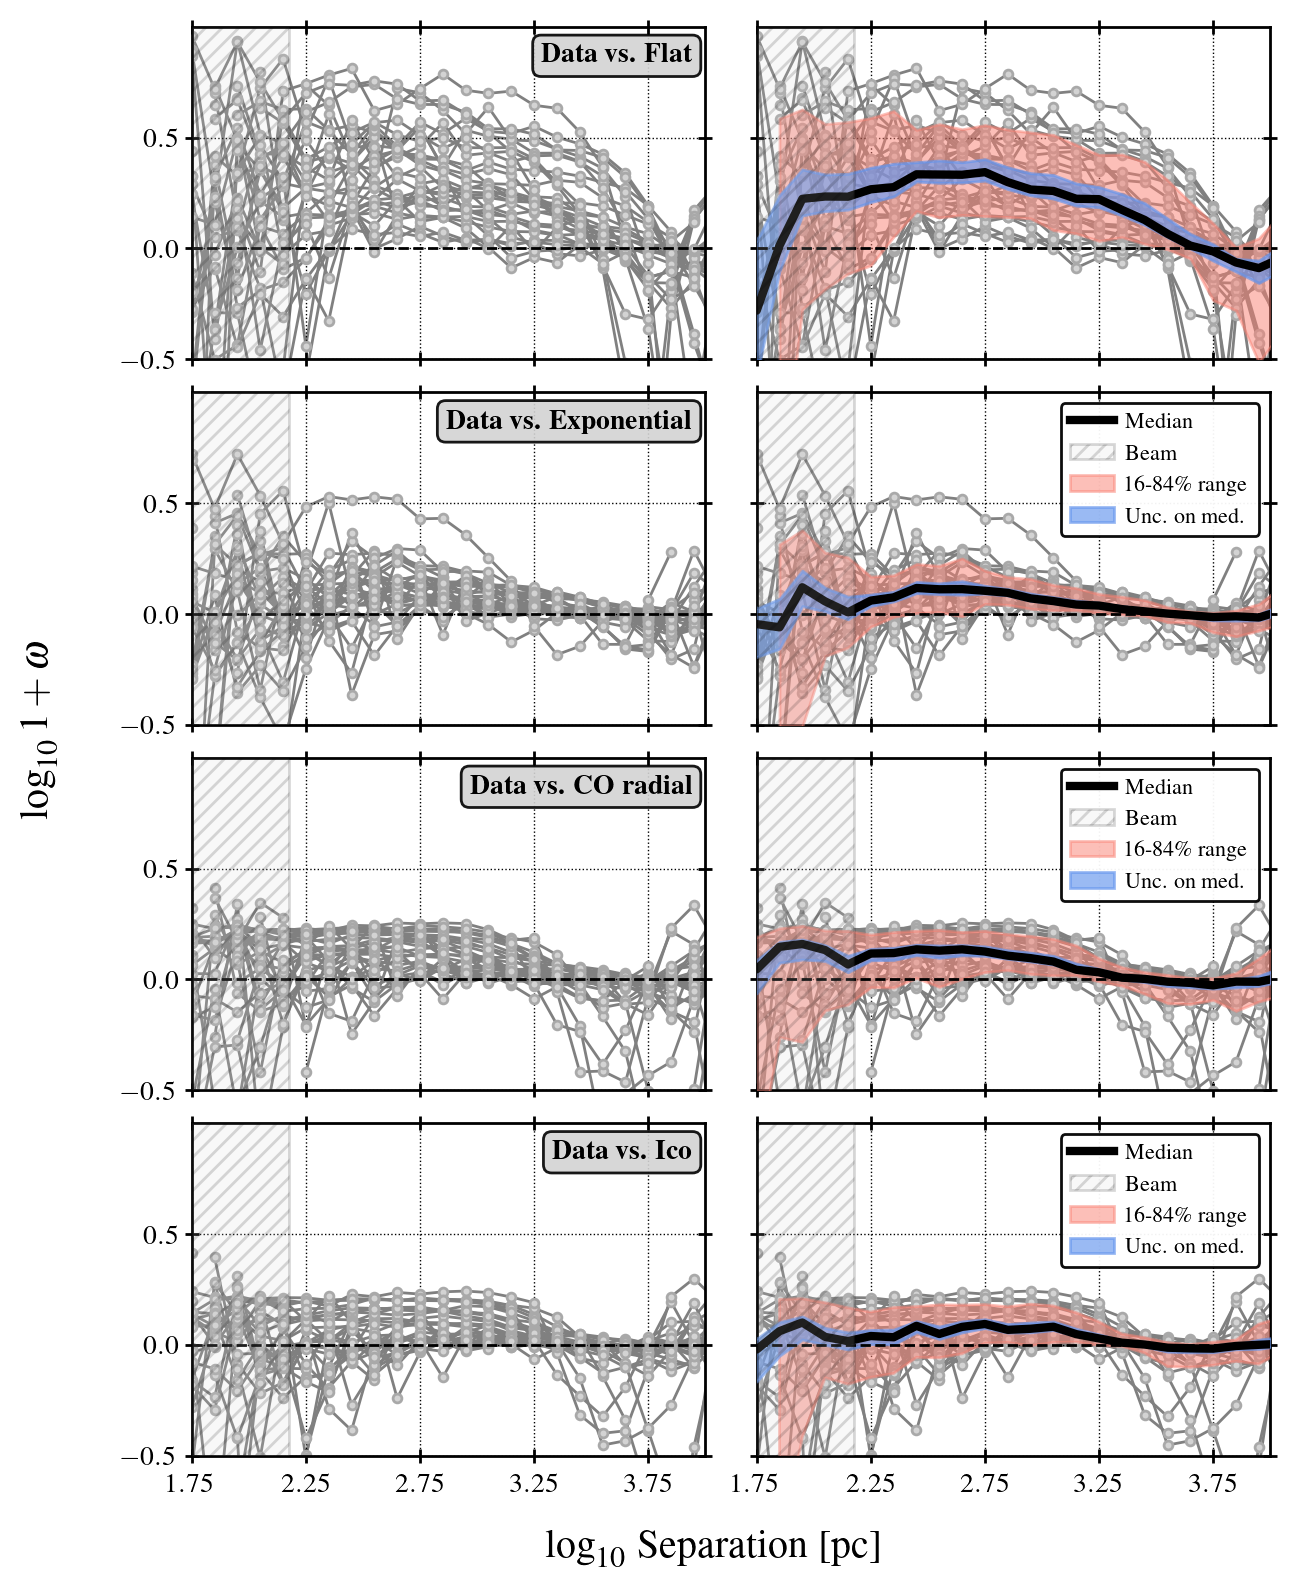

In [121]:
png_name = '../plots/twopt_multipanel.png'

npanels = 6
ncol = 2
nrow = 4
ticklength = 5

xmin = +1.75
xmax = +4.0
ymin = -0.5
ymax = +1.0
xticks = np.arange(xmin,xmax,0.5)
yticks = np.arange(ymin,ymax,0.5)

mpl_setup('paper-1/1', aspect=4./3., fs=12)

fig, axes = plt.subplots(
    nrow, ncol, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

axes = axes.ravel()

xlabel = r'$\log_{10}$ Separation [pc]'
ylabel = r'$\log_{10} 1 + \omega$'

fig.text(0.015, 0.5, ylabel, va='center', ha='center', rotation='vertical', fontsize='large')
fig.text(0.5, 0.06, xlabel, va='center', ha='center', rotation='horizontal', fontsize='large')

rows_done = 0
counter = 0

beam_scale = np.log10(150.)

for iax, ax in enumerate(axes):
    
    axes[iax].set_xlim([xmin,xmax])
    axes[iax].set_xscale('linear')
    axes[iax].set_ylim([ymin,ymax])
    axes[iax].set_xticks(xticks)
    axes[iax].set_yticks(yticks)
    axes[iax].tick_params(direction='inout', length=ticklength)
       
    axes[iax].grid(True, linestyle='dotted',linewidth=0.5,color='black')

    plot_main_legend = False
    plot_bbox = False
    plot_aggregate = False
    
    if counter == 0:
        this_label = r'\textbf{Data vs. Flat}'
        plot_bbox = True
        this_tab_tag = 'realvsflat'        
        
    if counter == 1:
        this_label = r'\textbf{Data vs. Flat}'
        this_tab_tag = 'realvsflat'
        plot_aggregate = True        
        
        agg_16 = realvsflat_16
        agg_50 = realvsflat_50
        agg_84 = realvsflat_84
        agg_lo = realvsflat_errlo
        agg_hi = realvsflat_errhi        

    if counter == 2:
        this_label = r'\textbf{Data vs. Exponential}'
        this_tab_tag = 'realvsexp'        
        plot_bbox = True
        
    if counter == 3:
        this_label = r'\textbf{Data vs. Exponential }'
        this_tab_tag = 'realvsexp'
        plot_aggregate = True        

        agg_16 = realvsexp_16
        agg_50 = realvsexp_50
        agg_84 = realvsexp_84
        agg_lo = realvsexp_errlo
        agg_hi = realvsexp_errhi
        plot_main_legend=True

    if counter == 4:
        this_label = r'\textbf{Data vs. CO radial}'
        this_tab_tag = 'realvsrad'
        plot_bbox = True
        
    if counter == 5:
        this_label = r'\textbf{Data vs. CO radial}'
        this_tab_tag = 'realvsrad'
        plot_aggregate = True

        agg_16 = realvsrad_16
        agg_50 = realvsrad_50
        agg_84 = realvsrad_84
        agg_lo = realvsrad_errlo
        agg_hi = realvsrad_errhi
        plot_main_legend=True

    if counter == 6:
        this_label = r'\textbf{Data vs. Ico}'
        this_tab_tag = 'realvsIco'
        plot_bbox = True

    if counter == 7:
        this_label = r'\textbf{Data vs. Ico}'
        this_tab_tag = 'realvsIco'
        plot_aggregate = True

        agg_16 = realvsIco_16
        agg_50 = realvsIco_50
        agg_84 = realvsIco_84
        agg_lo = realvsIco_errlo
        agg_hi = realvsIco_errhi
        plot_main_legend=True

    counter += 1
    i = 0
    
    axes[iax].plot([xmin,xmax],[0.,0.],color='black',linestyle='dashed',zorder=7)
    
    for this_source in corr_dict.keys():
        if corr_dict[this_source]['nclouds'] < nthresh:
            continue
        this_tab = corr_dict[this_source][this_tab_tag]
        
        this_x = np.log10(this_tab['xgeo'])
        this_y = np.log10(this_tab['twopt'])

        axes[iax].scatter(this_x,this_y,marker='o',s=10,
                          edgecolor='darkgray',facecolor='lightgray',
                          zorder=2)
        
        axes[iax].plot(this_x,this_y,zorder=1,linestyle='solid',color='gray')
        
    axes[iax].fill_betweenx(np.array([ymin,ymax]),xmin+np.array([0.,0.]),
                            (beam_scale)+np.array([0.,0.]),
                            hatch='////',facecolor='lightgray',alpha=0.15,
                            zorder=8,edgecolor=r'black',label=r'Beam')
        
    if plot_aggregate:
        agg_x = bins_xgeo            
        axes[iax].fill_between(np.log10(agg_x),np.log10(agg_16),np.log10(agg_84),
                               color='salmon',zorder=3,alpha=0.5, label=r'16-84\% range')
        agg_yerrlo = agg_50 - agg_lo
        agg_yerrhi = agg_50 + agg_hi
        axes[iax].fill_between(np.log10(agg_x), np.log10(agg_yerrlo), np.log10(agg_yerrhi),
                               color='cornflowerblue',zorder=4,alpha=0.65, label=r'Unc. on med.')
        
        axes[iax].plot(np.log10(agg_x), np.log10(agg_50),linestyle='solid',color='black',
                       zorder=5, linewidth=3, label=r'Median')
    
    bbox_props = dict(boxstyle="round", fc="lightgray", ec='black',alpha=0.9)
    yval = 0.95    

    if plot_bbox:
        ax.text(0.975, yval, this_label,
                ha='right', va='top',
                transform=ax.transAxes,
                size='small', bbox=bbox_props,
                zorder=5)
    
    if plot_main_legend:
        axes[iax].legend(fancybox=True, framealpha=0.95, loc='upper right', 
            ncol=1, fontsize=8, handlelength=2)    
        
fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3492696510.py:108: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3492696510.py:108: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3492696510.py:108: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3492696510.py:108: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3492696510.py:108: RuntimeWarning: invalid value encountered in log10
  this_y = np.log10(this_tab['twopt'])
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3492696510.py:108: RuntimeWarning: invalid value encountered in l

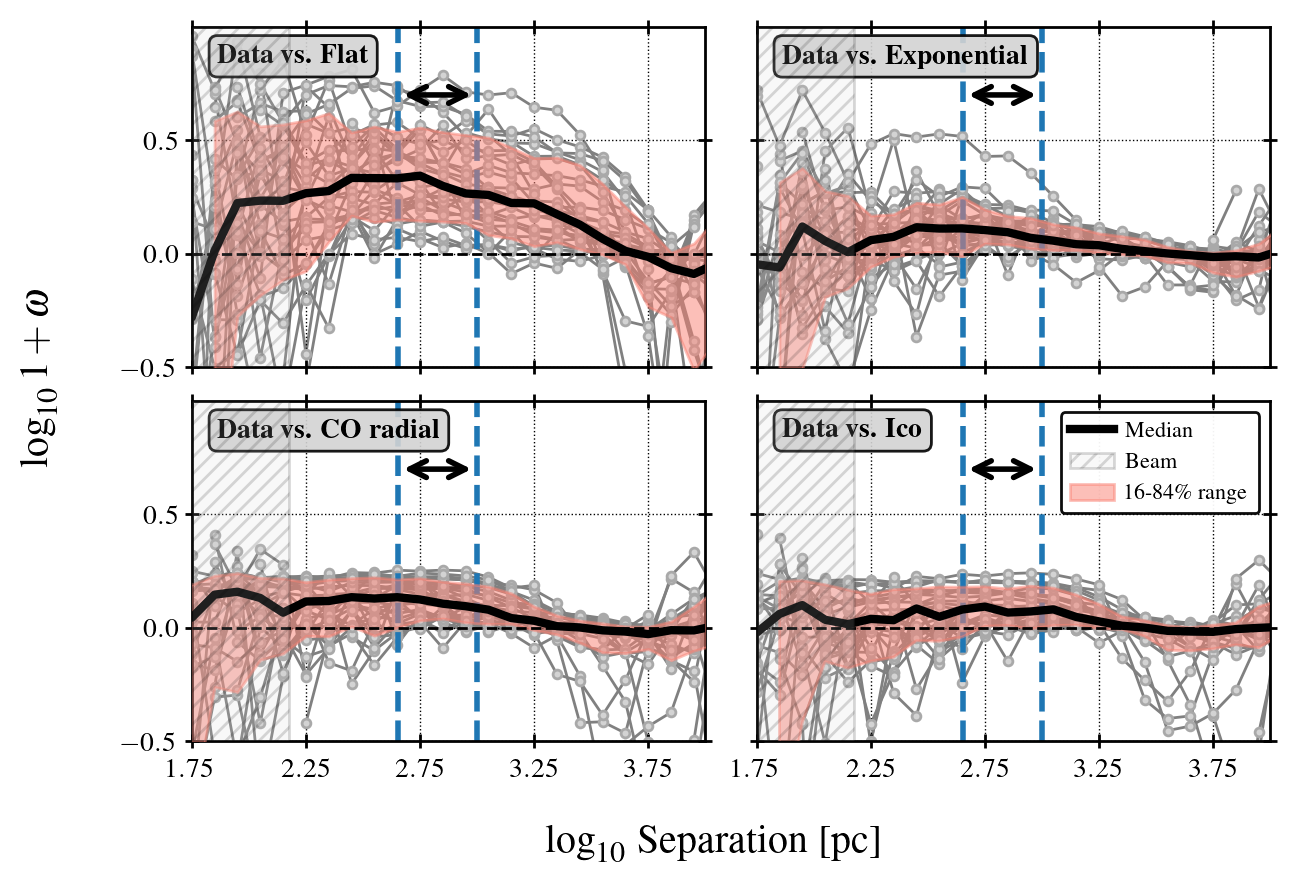

In [122]:
png_name = '../plots/twopt_multipanel_2x2.png'

npanels = 6
ncol = 2
nrow = 2
ticklength = 5

xmin = +1.75
xmax = +4.0
ymin = -0.5
ymax = +1.0
xticks = np.arange(xmin,xmax,0.5)
yticks = np.arange(ymin,ymax,0.5)

mpl_setup('paper-1/1', aspect=2./3., fs=12)

fig, axes = plt.subplots(
    nrow, ncol, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

axes = axes.ravel()

xlabel = r'$\log_{10}$ Separation [pc]'
ylabel = r'$\log_{10} 1 + \omega$'

fig.text(0.015, 0.5, ylabel, va='center', ha='center', rotation='vertical', fontsize='large')
fig.text(0.5, 0.0, xlabel, va='center', ha='center', rotation='horizontal', fontsize='large')

rows_done = 0
counter = 0

beam_scale = np.log10(150.)

plot_scale_range = True
for iax, ax in enumerate(axes):
    
    axes[iax].set_xlim([xmin,xmax])
    axes[iax].set_xscale('linear')
    axes[iax].set_ylim([ymin,ymax])
    axes[iax].set_xticks(xticks)
    axes[iax].set_yticks(yticks)
    axes[iax].tick_params(direction='inout', length=ticklength)
       
    axes[iax].grid(True, linestyle='dotted',linewidth=0.5,color='black')

    plot_main_legend = False
    plot_bbox = True
    plot_aggregate = False
        
    if counter == 0:
        this_label = r'\textbf{Data vs. Flat}'
        this_tab_tag = 'realvsflat'
        plot_aggregate = True        
        
        agg_16 = realvsflat_16
        agg_50 = realvsflat_50
        agg_84 = realvsflat_84
        agg_lo = realvsflat_errlo
        agg_hi = realvsflat_errhi        
        
    if counter == 1:
        this_label = r'\textbf{Data vs. Exponential }'
        this_tab_tag = 'realvsexp'
        plot_aggregate = True        

        agg_16 = realvsexp_16
        agg_50 = realvsexp_50
        agg_84 = realvsexp_84
        agg_lo = realvsexp_errlo
        agg_hi = realvsexp_errhi
        plot_main_legend=False

    if counter == 2:
        this_label = r'\textbf{Data vs. CO radial}'
        this_tab_tag = 'realvsrad'
        plot_aggregate = True

        agg_16 = realvsrad_16
        agg_50 = realvsrad_50
        agg_84 = realvsrad_84
        agg_lo = realvsrad_errlo
        agg_hi = realvsrad_errhi
        plot_main_legend=False

    if counter == 3:
        this_label = r'\textbf{Data vs. Ico}'
        this_tab_tag = 'realvsIco'
        plot_aggregate = True

        agg_16 = realvsIco_16
        agg_50 = realvsIco_50
        agg_84 = realvsIco_84
        agg_lo = realvsIco_errlo
        agg_hi = realvsIco_errhi
        plot_main_legend=True

    counter += 1
    i = 0
    
    axes[iax].plot([xmin,xmax],[0.,0.],color='black',linestyle='dashed',zorder=7)
    
    for this_source in corr_dict.keys():
        if corr_dict[this_source]['nclouds'] < nthresh:
            continue
        this_tab = corr_dict[this_source][this_tab_tag]
        
        this_x = np.log10(this_tab['xgeo'])
        this_y = np.log10(this_tab['twopt'])

        axes[iax].scatter(this_x,this_y,marker='o',s=10,
                          edgecolor='darkgray',facecolor='lightgray',
                          zorder=2)
        
        axes[iax].plot(this_x,this_y,zorder=1,linestyle='solid',color='gray')
        
    axes[iax].fill_betweenx(np.array([ymin,ymax]),xmin+np.array([0.,0.]),
                            (beam_scale)+np.array([0.,0.]),
                            hatch='////',facecolor='lightgray',alpha=0.15,
                            zorder=8,edgecolor=r'black',label=r'Beam')
        
    if plot_aggregate:
        agg_x = bins_xgeo            
        axes[iax].fill_between(np.log10(agg_x),np.log10(agg_16),np.log10(agg_84),
                               color='salmon',zorder=3,alpha=0.5, label=r'16-84\% range')
        # agg_yerrlo = agg_50 - agg_lo
        # agg_yerrhi = agg_50 + agg_hi
        # axes[iax].fill_between(np.log10(agg_x), np.log10(agg_yerrlo), np.log10(agg_yerrhi),
        #                        color='cornflowerblue',zorder=4,alpha=0.65, label=r'Unc. on med.')
        
        axes[iax].plot(np.log10(agg_x), np.log10(agg_50),linestyle='solid',color='black',
                       zorder=5, linewidth=3, label=r'Median')
    
    bbox_props = dict(boxstyle="round", fc="lightgray", ec='black',alpha=0.9)
    yval = 0.95    

    if plot_bbox:
        ax.text(0.05, yval, this_label,
                ha='left', va='top',
                transform=ax.transAxes,
                size='small', bbox=bbox_props,
                zorder=5)
    
    if plot_main_legend:
        axes[iax].legend(fancybox=True, framealpha=0.95, loc='upper right', 
            ncol=1, fontsize=8, handlelength=2)    
        
    if plot_scale_range:
        if iax in [0,1,2,3]:
            ax.axvline(np.log10(450), ls='dashed', lw=2)
            ax.axvline(np.log10(1000), ls='dashed', lw=2)            
            arrow = FancyArrowPatch(
                (np.log10(450), 0.7), (3, 0.7),
                arrowstyle='<->', color='black', lw=2, mutation_scale=15, zorder=10)
            ax.add_patch(arrow)
        else:
            ax.axvline(np.log10(450), ls='dashed', lw=2)
            arrow = FancyArrowPatch(
                (np.log10(450), 0.7), (3, 0.7),
                arrowstyle='->', color='black', lw=2, mutation_scale=15, zorder=10)
            ax.add_patch(arrow)
        
fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

Compare the slope using different controls

In [123]:
# import literature values
menon_slope_young = -1*np.array([0.3, 0.5, 2.4, 0.2,0.2, 0.3])
menon_slope_old = -1 * np.array([0.2, 0.0, 0.2, 0.3, 0.0, 0.0, 0.1, 0.0, 0.4])

print('Median of slope of power-law tail for young clusters:', np.nanmedian(menon_slope_young))
print('Median of slope of power-law for old clusters:', np.nanmedian(menon_slope_old))

Median of slope of power-law tail for young clusters: -0.3
Median of slope of power-law for old clusters: -0.1


/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/1354896537.py:8: RuntimeWarning: invalid value encountered in log10
  tpcf = np.log10(corr_dict[this_source]['realvsflat']['twopt'])


1.6033320460908316


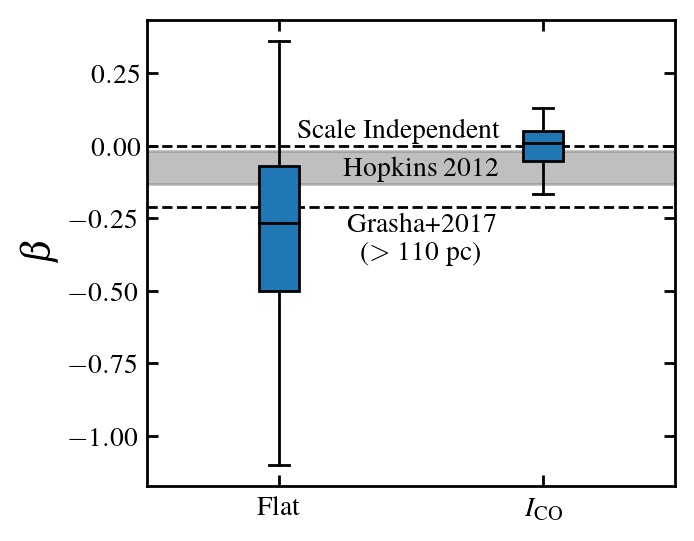

In [124]:
sep_dist = np.log10(corr_dict['ic1954']['realvsflat']['xgeo'])

slopes_flat = []; slopes_Ico = []
for this_source in corr_dict.keys():
    if corr_dict[this_source]['nclouds'] < nthresh:
        continue
    # calculate slope with flat control
    tpcf = np.log10(corr_dict[this_source]['realvsflat']['twopt'])
    mask = (tpcf>0) & (~np.isnan(tpcf))
    amp_500pc = np.interp(np.log10(500), sep_dist[mask], tpcf[mask])
    amp_1kpc = np.interp(np.log10(1000), sep_dist[mask], tpcf[mask])
    slope = -(np.log10(amp_500pc) - np.log10(amp_1kpc))/(np.log10(1000/500))
    slopes_flat.append(slope)
    
    # calculate slope with Ico control
    tpcf = corr_dict[this_source]['realvsIco']['twopt']
    mask = (tpcf>0) & (~np.isnan(tpcf))
    amp_500pc = np.interp(np.log10(500), sep_dist[mask], tpcf[mask], left=np.nan, right=np.nan)
    amp_1kpc = np.interp(np.log10(1000), sep_dist[mask], tpcf[mask], left=np.nan, right=np.nan)
    slope = -(np.log10(amp_500pc) - np.log10(amp_1kpc))/(np.log10(1000/500))
    slopes_Ico.append(slope)

slopes_flat = np.array(slopes_flat); slopes_Ico = np.array(slopes_Ico)
print(amp_500pc)

# make the box plot of the slope distribution
mpl_setup('paper-1/2', aspect=4/4.5, fs=12)
fig = plt.figure()
ax = plt.subplot(111)
# ax.axvline(-1, ls='dashed', color='black', lw=1)
ax.axhline(-0.21, ls='dashed', color='black', lw=1)
# ax.axhline(-0.05, ls='dashed', color='black', lw=1)
ax.axhline(0, ls='dashed', color='black', lw=1)
ax.set_ylabel(r'$\beta$')
ax.annotate('Grasha+2017\n'+r'($>$ 110 pc)', (0.52, 0.53), xycoords='axes fraction', ha='center', va='center', rotation=0, fontsize=10)
ax.annotate('Hopkins 2012', (0.52, 0.68), xycoords='axes fraction', ha='center', va='center', rotation=0, fontsize=10)
ax.annotate('Scale Independent', (0.48, 0.76), xycoords='axes fraction', ha='center', va='center', rotation=0, fontsize=10)
box = ax.boxplot([slopes_flat, slopes_Ico], 
            vert=True, 
           labels=['Flat', r'$I_{\mathrm{CO}}$'], 
           medianprops=dict(color='black'),
           patch_artist=True, showfliers=False, whis=1.5)
# get the xlimit 
xmin, xmax = ax.get_xlim()
ax.fill_between([xmin, xmax], -0.016, -0.13, color='gray', alpha=0.5)

plt.savefig('../plots/slopes_box_plot.png', bbox_inches='tight', dpi=300)


prediction from Hopkins+2012

-0.016350359038775835 -0.04989456325320738 -0.13366658163860184

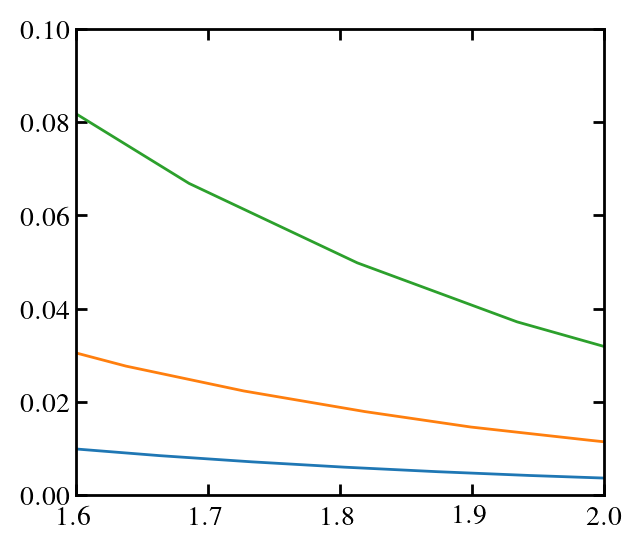

In [125]:
model1 = Table.read('../../literature/Hopkins_2012_model1.csv', names=['r', 'xsi'], data_start=0)
model2 = Table.read('../../literature/Hopkins_2012_model2.csv', names=['r', 'xsi'], data_start=0)
model3 = Table.read('../../literature/Hopkins_2012_model3.csv', names=['r', 'xsi'], data_start=0)


fig = plt.figure()
ax = plt.subplot(111)
ax.set_xlim(1.6, 2); ax.set_ylim(0, 0.1)
ax.plot(model1['r'], np.log10(1+10**model1['xsi']))
ax.plot(model2['r'], np.log10(1+10**model2['xsi']))
ax.plot(model3['r'], np.log10(1+10**model3['xsi']))
amp = np.log10(1+10**model1['xsi'])
idx1 = np.where(model1['r']>=1.6)[0][0]
idx2 = np.where(model1['r']<=2)[0][-1]
p1, _= np.polyfit(model1['r'][idx1:idx2], amp[idx1:idx2], deg=1)
amp = np.log10(1+10**model2['xsi'])
idx1 = np.where(model2['r']>=1.6)[0][0]
idx2 = np.where(model2['r']<=2)[0][-1]
p2, _= np.polyfit(model2['r'][idx1:idx2], amp[idx1:idx2], deg=1)
amp = np.log10(1+10**model3['xsi'])
idx1 = np.where(model3['r']>=1.6)[0][0]
idx2 = np.where(model3['r']<=2)[0][-1]
p3, _= np.polyfit(model3['r'][idx1:idx2], amp[idx1:idx2], deg=1)
print(p1, p2, p3)

Plot the comparison between Data vs CO radial and Data vs Ico

In [126]:
realvsflat_fid = np.array([])
realvsexp_fid = np.array([])
flatvsexp_fid = np.array([])
realvsrad_fid = np.array([])
realvsIco_fid = np.array([])

i = 0
for this_source in source_list:
    if corr_dict[this_source]['nclouds'] < nthresh:
        continue
    i = i + 1
    realvsflat_fid = np.append(realvsflat_fid, corr_dict[this_source]['realvsflat_atfid'])
    realvsexp_fid = np.append(realvsexp_fid, corr_dict[this_source]['realvsexp_atfid'])
    realvsrad_fid = np.append(realvsrad_fid, corr_dict[this_source]['realvsrad_atfid'])
    realvsIco_fid = np.append(realvsIco_fid, corr_dict[this_source]['realvsIco_atfid'])
print(i)

30


Check a few galaxies with higher radial over Ico ratio

In [127]:
ratio = realvsrad_fid - realvsIco_fid
top4_idx = np.argpartition(ratio, -4)[-4:]
print(top4_idx)

print(source_bin[1], source_bin[21], source_bin[6], source_bin[26])

[ 6 26 21  4]
ic5273 ngc4548 ngc1511 ngc5128


/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in double_scalars
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = sub

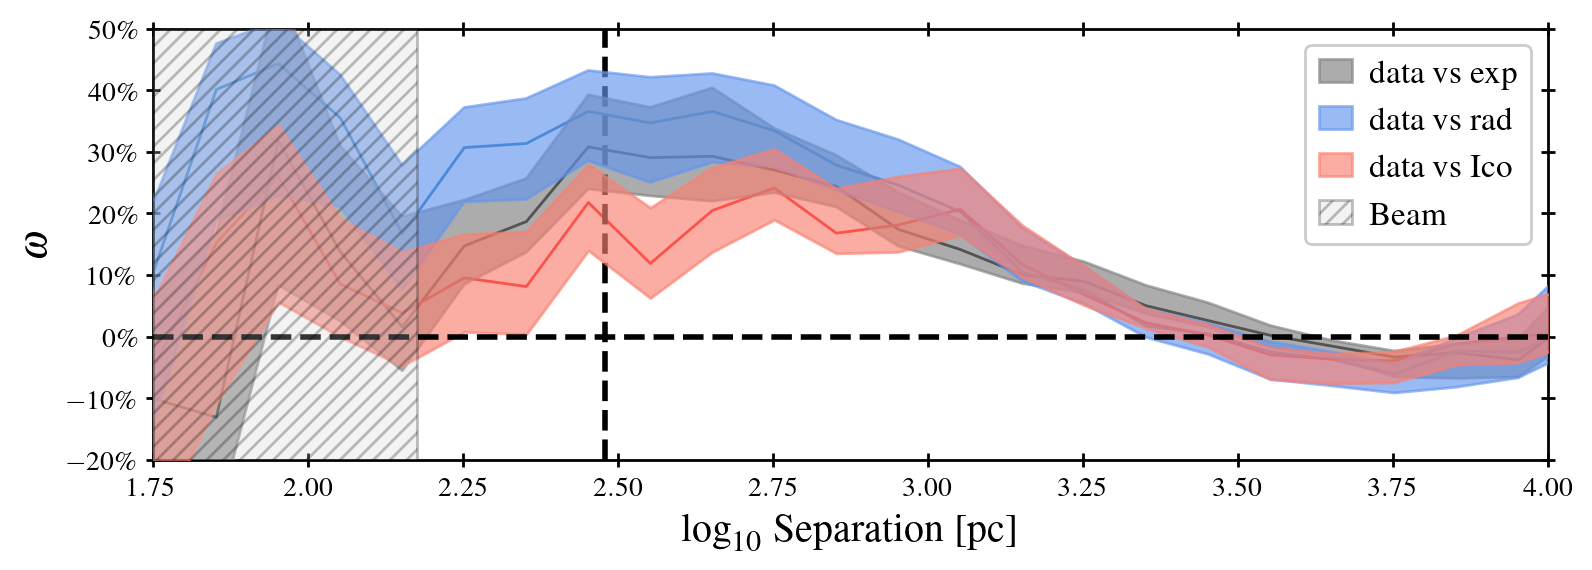

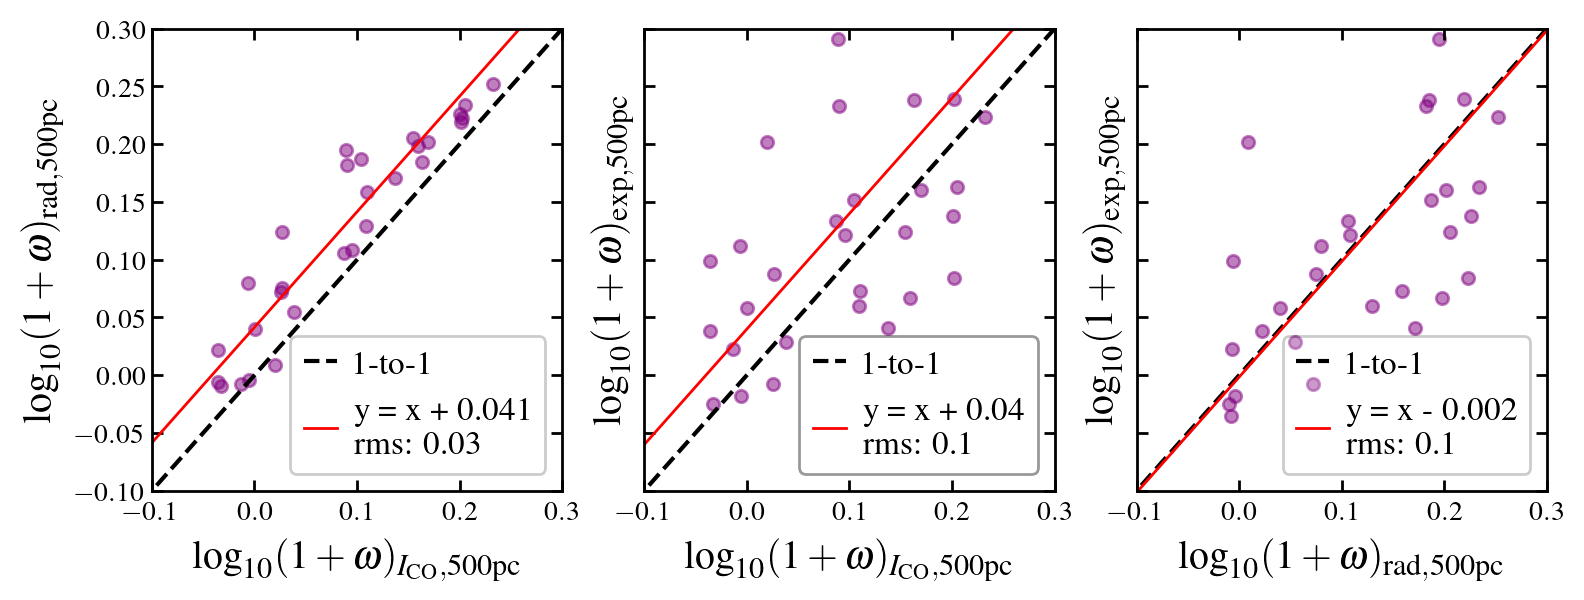

In [128]:
%matplotlib inline

def log_prop_fit(x, a):
    return x+a


xmin = +1.75
xmax = +4.0
ymin = 0.8-1
ymax = 1.5-1

fig = plt.figure(figsize=(9,2.8))
ax = plt.subplot(111)
ax.set_ylabel(r'$\omega$'); ax.set_xlabel(r'$\log_{10}$ Separation [pc]')

source_bin = [source for source in source_list if source not in source_nthresh]
_, idx, _ = np.intersect1d(np.array(source_list), np.array(source_bin), return_indices=True)

unc_method = 'error propagation'

bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict, source_bin, tpcf_tag='realvsexp', unc_method=unc_method)
ax.plot(np.log10(bins_xgeo), (corr_agg_50-1), color='black')
ax.fill_between(np.log10(bins_xgeo), ((corr_agg_50-corr_agg_errlo)-1),((corr_agg_50+corr_agg_errhi)-1),
                    color='gray',zorder=4,alpha=0.65, label='data vs exp')
bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict, source_bin, tpcf_tag='realvsrad', unc_method=unc_method)
ax.plot(np.log10(bins_xgeo), (corr_agg_50-1))
ax.fill_between(np.log10(bins_xgeo), ((corr_agg_50-corr_agg_errlo)-1),((corr_agg_50+corr_agg_errhi)-1),
                    color='cornflowerblue',zorder=4,alpha=0.65, label='data vs rad')
bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict, source_bin, tpcf_tag='realvsIco', unc_method=unc_method)
ax.plot(np.log10(bins_xgeo), (corr_agg_50-1), color='red')
ax.fill_between(np.log10(bins_xgeo), ((corr_agg_50-corr_agg_errlo)-1),((corr_agg_50+corr_agg_errhi)-1),
                    color='salmon',zorder=4,alpha=0.65, label='data vs Ico')
ax.fill_betweenx(np.array([ymin,ymax]),xmin+np.array([0.,0.]),
                        (beam_scale)+np.array([0.,0.]),
                        hatch='////',facecolor='lightgray',alpha=0.25,
                        zorder=8,edgecolor=r'black',label=r'Beam')

beam_scale = np.log10(150.)
ax.set_xlim(xmin,xmax)
ax.set_ylim(ymin,ymax)
ax.tick_params(direction='inout', length=ticklength)
# plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
from matplotlib.ticker import PercentFormatter
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0)) 

plt.legend()
ax.axvline(2.48, ls='dashed', color='black', lw=2)
ax.axhline(0.0, ls='dashed', color='black', lw=2, zorder=6)
plt.savefig('../plots/twopt_zoomin_comprs_percent.png', bbox_inches='tight', dpi=300)

xmin = -0.1; xmax = 0.3
fig, axes = plt.subplots(1,3,figsize=(9,3), sharey=True)
axes = axes.ravel()
ax = axes[0]
ax.set_xlabel(r'$\log_{10}(1 + \omega)_{I_{\mathrm{CO}}, \mathrm{500 pc}}$'); ax.set_ylabel(r'$\log_{10}(1 + \omega)_{\mathrm{rad, 500 pc}}$')
ax.scatter(realvsIco_fid, realvsrad_fid, marker='o', s=20, color='purple', alpha=0.5)
ax.set_xlim(xmin, xmax); ax.set_ylim(xmin, xmax)
# plot the 1-to-1 relation
ax.plot([-0.5, 1], [-0.5, 1], ls='dashed', lw=1.5, color='black', label='1-to-1')
# fit a proportional relation
x = realvsIco_fid; y = realvsrad_fid
popt, pcov = curve_fit(log_prop_fit, x, y)
x_fit = np.arange(-1, 1, 0.1); y_fit = log_prop_fit(x_fit, *popt)
formatted_coeff = "{:.2g}".format(popt[0])
# calculate the rms 
y_theory = log_prop_fit(x, *popt)
rms = np.sqrt(np.mean((y - y_theory) ** 2)); rms_formt = "{:.1g}".format(rms)
ax.plot(x_fit, y_fit, color='red', label='y = x + '+formatted_coeff+'\n rms: '+rms_formt)
ax.legend(loc='lower right')

ax = axes[1]
ax.set_xlabel(r'$\log_{10}(1 + \omega)_{I_{\mathrm{CO}}, \mathrm{500 pc}}$'); ax.set_ylabel(r'$\log_{10}(1 + \omega)_{\mathrm{exp, 500 pc}}$')
ax.scatter(realvsIco_fid, realvsexp_fid, marker='o', s=20, color='purple', alpha=0.5)
ax.set_xlim(xmin, xmax); ax.set_ylim(xmin, xmax)
# plot the 1-to-1 relation
ax.plot([-0.5, 1], [-0.5, 1], ls='dashed', lw=1.5, color='black', label='1-to-1')
# fit a proportional relation
x = realvsIco_fid; y = realvsexp_fid
popt, pcov = curve_fit(log_prop_fit, x, y)
x_fit = np.arange(-1, 1, 0.1); y_fit = log_prop_fit(x_fit, *popt)
formatted_coeff = "{:.2g}".format(popt[0])
# calculate the rms 
y_theory = log_prop_fit(x, *popt)
rms = np.sqrt(np.mean((y - y_theory) ** 2)); rms_formt = "{:.1g}".format(rms)
ax.plot(x_fit, y_fit, color='red', label='y = x + '+formatted_coeff+'\n rms: '+rms_formt)
ax.legend(framealpha=0.4)

ax = axes[2]
ax.set_xlabel(r'$\log_{10}(1 + \omega)_{\mathrm{rad, 500 pc}}$'); ax.set_ylabel(r'$\log_{10}(1 + \omega)_{\mathrm{exp, 500 pc}}$')
ax.scatter(realvsrad_fid, realvsexp_fid, marker='o', s=20, color='purple', alpha=0.5)
ax.set_xlim(xmin, xmax); ax.set_ylim(xmin, xmax)
# plot the 1-to-1 relation
ax.plot([-0.5, 1], [-0.5, 1], ls='dashed', lw=1.5, color='black', label='1-to-1')
# fit a proportional relation
x = realvsrad_fid; y = realvsexp_fid
popt, pcov = curve_fit(log_prop_fit, x, y)
x_fit = np.arange(-1, 1, 0.1); y_fit = log_prop_fit(x_fit, *popt)
formatted_coeff = "{:.1g}".format(-popt[0])
# calculate the rms 
y_theory = log_prop_fit(x, *popt)
rms = np.sqrt(np.mean((y - y_theory) ** 2)); rms_formt = "{:.1g}".format(rms)
ax.plot(x_fit, y_fit, color='red', label='y = x - '+formatted_coeff+'\n rms: '+rms_formt)
ax.legend(loc='lower right')

fig.subplots_adjust(wspace=0.2)
plt.savefig('../plots/twopt_fid_comprs.png', bbox_inches='tight', dpi=300)

Correlate the flat fiducial amplitude with the scale length of the stellar disk

Examples for specific galaxies

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/1160551158.py:14: RuntimeWarning: invalid value encountered in log10
  this_y_log = np.log10(this_y)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/1160551158.py:15: RuntimeWarning: invalid value encountered in log10
  this_y_err_upp = np.log10(this_y+this_y_err) - this_y_log
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1061: UserWarning: Warning: converting a masked element to nan.
  x = np.asanyarray(x)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1333: UserWarning: Warning: converting a masked element to nan.
  return np.asarray(x, float)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/1160551158.py:26: RuntimeWarning: invalid value encountered in log10
  this_y_log = np.log10(this_y)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/1160551158.py:27: RuntimeWarning: inva

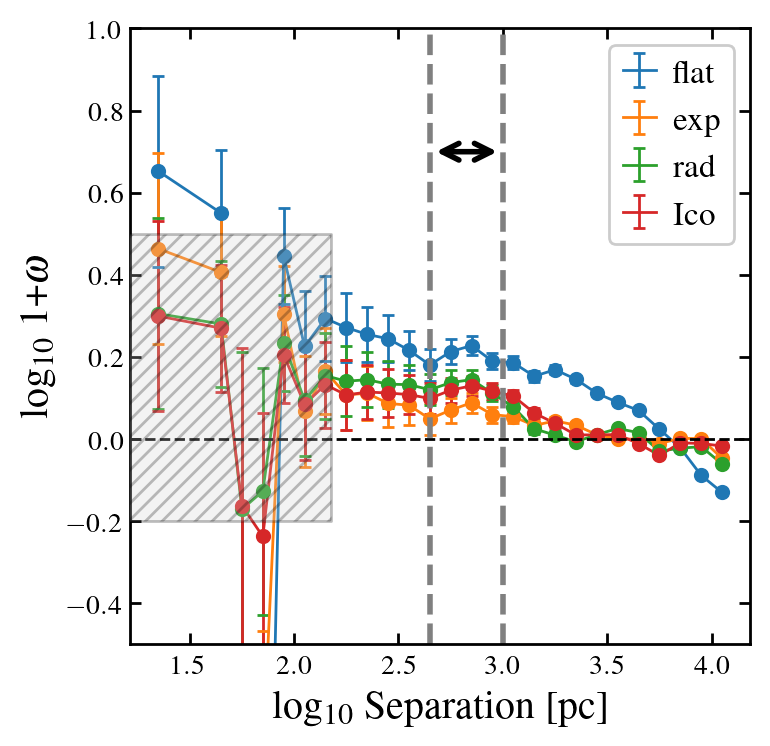

In [129]:
sources = ['ngc3621', 'ngc1097', 'ngc0628']
sources = ['ngc3627']

fig = plt.figure(figsize=(4,4))
ax = plt.subplot(111)
ax.set_ylim(-0.5, 1)
plt.xlabel(r'log$_{10}$ Separation [pc]'); plt.ylabel(r'log$_{10}$ 1+$\omega$')

for source in sources:
    # plot the flat
    this_x = np.log10(corr_dict[source]['realvsflat']['xgeo'])
    this_y = corr_dict[source]['realvsflat']['twopt']
    this_y_err = corr_dict[source]['realvsflat']['twopt_err']
    this_y_log = np.log10(this_y)
    this_y_err_upp = np.log10(this_y+this_y_err) - this_y_log
    this_y_err_lo = this_y_err_upp
    mask = np.where(~ ((np.isnan(this_y)) | (this_y==-np.inf)))
    ax.scatter(this_x[mask],this_y_log[mask],marker='o',s=20,
                      zorder=2)
    ax.errorbar(this_x[mask],this_y_log[mask], yerr=[this_y_err_lo[mask], this_y_err_upp[mask]], zorder=1,linestyle='solid', label='flat')
#     plt.plot(x, y, marker='o', label=source)
    # plot the exponential
    this_x = np.log10(corr_dict[source]['realvsexp']['xgeo'])
    this_y = corr_dict[source]['realvsexp']['twopt']
    this_y_err = corr_dict[source]['realvsexp']['twopt_err']
    this_y_log = np.log10(this_y)
    this_y_err_upp = np.log10(this_y+this_y_err) - this_y_log
    this_y_err_lo = this_y_err_upp
    mask = np.where(~ ((np.isnan(this_y)) | (this_y==-np.inf)))
    ax.scatter(this_x[mask],this_y_log[mask],marker='o',s=20,
                      zorder=2)
    ax.errorbar(this_x[mask],this_y_log[mask], yerr=[this_y_err_lo[mask], this_y_err_upp[mask]], zorder=1,linestyle='solid', label='exp')
    # plot the radial
    this_x = np.log10(corr_dict[source]['realvsrad']['xgeo'])
    this_y = corr_dict[source]['realvsrad']['twopt']
    this_y_err = corr_dict[source]['realvsrad']['twopt_err']
    this_y_log = np.log10(this_y)
    this_y_err_upp = np.log10(this_y+this_y_err) - this_y_log
    this_y_err_lo = this_y_err_upp
    mask = np.where(~ ((np.isnan(this_y)) | (this_y==-np.inf)))
    ax.scatter(this_x[mask],this_y_log[mask],marker='o',s=20,
                      zorder=2)
    ax.errorbar(this_x[mask],this_y_log[mask], yerr=[this_y_err_lo[mask], this_y_err_upp[mask]], zorder=1,linestyle='solid', label='rad')
    # plot the Ico
    this_x = np.log10(corr_dict[source]['realvsIco']['xgeo'])
    this_y = np.array(corr_dict[source]['realvsIco']['twopt'])
    this_y_err = np.array(corr_dict[source]['realvsIco']['twopt_err'])
    this_y_log = np.log10(this_y)
    this_y_err_upp = np.log10(this_y+this_y_err) - this_y_log
    this_y_err_lo = this_y_err_upp
    mask = np.where(~ ((np.isnan(this_y_log)) | (this_y_log==-np.inf)))
    ax.scatter(this_x[mask],this_y_log[mask],marker='o',s=20,
                      zorder=2)
    ax.errorbar(this_x[mask],this_y_log[mask], yerr=[this_y_err_lo[mask], this_y_err_upp[mask]], zorder=1,linestyle='solid', label='Ico')
ax.axhline(0.0, ls='dashed', color='black')
plt.legend(loc='upper right')
ax.set_xlim()
ax.fill_betweenx(np.array([ymin,ymax]),1.0+np.array([0.,0.]),
                        (beam_scale)+np.array([0.,0.]),
                        hatch='////',facecolor='lightgray',alpha=0.25,
                        zorder=8,edgecolor=r'black',label=r'Beam')
# add the arrow in between
ax.axvline(np.log10(450), ls='dashed', lw=2, color='gray')
ax.axvline(np.log10(1000), ls='dashed', lw=2, color='gray')            
arrow = FancyArrowPatch(
    (np.log10(450), 0.7), (3, 0.7),
    arrowstyle='<->', color='black', lw=2, mutation_scale=15)
ax.add_patch(arrow)

plt.savefig('../plots/ngc3627_twopt_example.png', bbox_inches='tight')


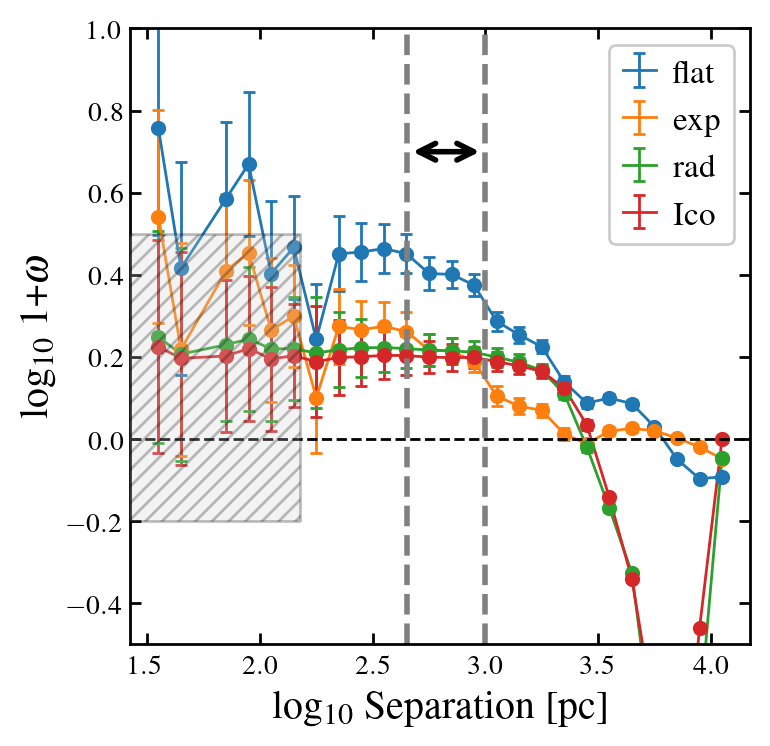

In [130]:
sources = ['ngc3621', 'ngc1097', 'ngc0628']
sources = ['ngc1097']

fig = plt.figure(figsize=(4,4))
ax = plt.subplot(111)
ax.set_ylim(-0.5, 1)
plt.xlabel(r'log$_{10}$ Separation [pc]'); plt.ylabel(r'log$_{10}$ 1+$\omega$')

for source in sources:
    # plot the flat
    this_x = np.log10(corr_dict[source]['realvsflat']['xgeo'])
    this_y = corr_dict[source]['realvsflat']['twopt']
    this_y_err = corr_dict[source]['realvsflat']['twopt_err']
    this_y_log = np.log10(this_y)
    this_y_err_upp = np.log10(this_y+this_y_err) - this_y_log
    this_y_err_lo = this_y_err_upp
    mask = np.where(~ ((np.isnan(this_y)) | (this_y==-np.inf)))
    ax.scatter(this_x[mask],this_y_log[mask],marker='o',s=20,
                      zorder=2)
    ax.errorbar(this_x[mask],this_y_log[mask], yerr=[this_y_err_lo[mask], this_y_err_upp[mask]], zorder=1,linestyle='solid', label='flat')
#     plt.plot(x, y, marker='o', label=source)
    # plot the exponential
    this_x = np.log10(corr_dict[source]['realvsexp']['xgeo'])
    this_y = corr_dict[source]['realvsexp']['twopt']
    this_y_err = corr_dict[source]['realvsexp']['twopt_err']
    this_y_log = np.log10(this_y)
    this_y_err_upp = np.log10(this_y+this_y_err) - this_y_log
    this_y_err_lo = this_y_err_upp
    mask = np.where(~ ((np.isnan(this_y)) | (this_y==-np.inf)))
    ax.scatter(this_x[mask],this_y_log[mask],marker='o',s=20,
                      zorder=2)
    ax.errorbar(this_x[mask],this_y_log[mask], yerr=[this_y_err_lo[mask], this_y_err_upp[mask]], zorder=1,linestyle='solid', label='exp')
    # plot the radial
    this_x = np.log10(corr_dict[source]['realvsrad']['xgeo'])
    this_y = corr_dict[source]['realvsrad']['twopt']
    this_y_err = corr_dict[source]['realvsrad']['twopt_err']
    this_y_log = np.log10(this_y)
    this_y_err_upp = np.log10(this_y+this_y_err) - this_y_log
    this_y_err_lo = this_y_err_upp
    mask = np.where(~ ((np.isnan(this_y)) | (this_y==-np.inf)))
    ax.scatter(this_x[mask],this_y_log[mask],marker='o',s=20,
                      zorder=2)
    ax.errorbar(this_x[mask],this_y_log[mask], yerr=[this_y_err_lo[mask], this_y_err_upp[mask]], zorder=1,linestyle='solid', label='rad')
    # plot the Ico
    this_x = np.log10(corr_dict[source]['realvsIco']['xgeo'])
    this_y = np.array(corr_dict[source]['realvsIco']['twopt'])
    this_y_err = np.array(corr_dict[source]['realvsIco']['twopt_err'])
    this_y_log = np.log10(this_y)
    this_y_err_upp = np.log10(this_y+this_y_err) - this_y_log
    this_y_err_lo = this_y_err_upp
    mask = np.where(~ ((np.isnan(this_y_log)) | (this_y_log==-np.inf)))
    ax.scatter(this_x[mask],this_y_log[mask],marker='o',s=20,
                      zorder=2)
    ax.errorbar(this_x[mask],this_y_log[mask], yerr=[this_y_err_lo[mask], this_y_err_upp[mask]], zorder=1,linestyle='solid', label='Ico')
ax.axhline(0.0, ls='dashed', color='black')
plt.legend(loc='upper right')
ax.set_xlim()
ax.fill_betweenx(np.array([ymin,ymax]),1.0+np.array([0.,0.]),
                        (beam_scale)+np.array([0.,0.]),
                        hatch='////',facecolor='lightgray',alpha=0.25,
                        zorder=8,edgecolor=r'black',label=r'Beam')
# add the arrow in between
ax.axvline(np.log10(450), ls='dashed', lw=2, color='gray')
ax.axvline(np.log10(1000), ls='dashed', lw=2, color='gray')            
arrow = FancyArrowPatch(
    (np.log10(450), 0.7), (3, 0.7),
    arrowstyle='<->', color='black', lw=2, mutation_scale=15)
ax.add_patch(arrow)

plt.savefig('../plots/ngc1097_twopt_example.png', bbox_inches='tight')


## Measure the average amplitude at ~ 300 pc scale. 

In [131]:
source_bin = [source for source in source_list if source not in source_nthresh]
print(len(source_bin))

realvsflat_fid = np.array([])
realvsexp_fid = np.array([])
flatvsexp_fid = np.array([])
realvsrad_fid = np.array([])
realvsIco_fid = np.array([])

for this_source in source_bin:
    realvsflat_fid = np.append(realvsflat_fid, corr_dict[this_source]['realvsflat_atfid'])
    realvsexp_fid = np.append(realvsexp_fid, corr_dict[this_source]['realvsexp_atfid'])
    realvsrad_fid = np.append(realvsrad_fid, corr_dict[this_source]['realvsrad_atfid'])
    realvsIco_fid = np.append(realvsIco_fid, corr_dict[this_source]['realvsIco_atfid'])


twopt_fid_amp = QTable()
twopt_fid_amp['name'] = source_bin
twopt_fid_amp['realvsflat'] = realvsflat_fid
twopt_fid_amp['realvsexp'] = realvsexp_fid
twopt_fid_amp['realvsrad'] = realvsrad_fid
twopt_fid_amp['realvsIco'] = realvsIco_fid


30


In [132]:
source_propt = sample_tab[np.isin(sample_tab['name'], np.array(source_bin))]

columns = ['size_reff', 'mh2_phangs', 'props_mstar', 'props_sfr', 'props_mhi']

# select a subset with one column in the selecting list
mask = [name in source_bin for name in source_propt['name']]
source_for_twopt = source_propt[mask]

print(source_for_twopt)
# print(twopt_fid_amp)

# source_for_twopt = source_for_twopt[columns]

  name   pgc  ... f_recvr faint_lab
              ...                  
------- ----- ... ------- ---------
 ic1954 13090 ...    70.7         0
 ic5273 70184 ...    56.1         0
ngc0253  2789 ...    85.8         0
ngc0628  5974 ...    64.5         0
ngc0685  6581 ...    36.5         0
ngc1097 10488 ...    82.7         0
ngc1511 14236 ...    81.0         0
ngc1546 14723 ...    91.6         0
ngc1637 15821 ...    83.5         0
ngc1792 16709 ...    88.5         0
    ...   ... ...     ...       ...
ngc4536 41823 ...    84.7         0
ngc4548 41934 ...    42.1         0
ngc4569 42089 ...    83.2         0
ngc4781 43902 ...    75.6         0
ngc4941 45165 ...    63.3         0
ngc5068 46400 ...    46.5         0
ngc5128 46957 ...    76.8         0
ngc5236 48082 ...    92.1         0
ngc5643 51969 ...    76.0         0
ngc7496 70588 ...    73.3         0
Length = 30 rows


In [133]:
from scipy.stats import pearsonr, spearmanr
import itertools

def corr_with_pvalues(df1, df2):
    # Get numeric columns and prepare a matrix structure in DataFrame format
    num_rows = df1.select_dtypes(include=[np.number]).columns
    num_cols = df2.select_dtypes(include=[np.number]).columns
    corr = pd.DataFrame(index=num_rows, columns=num_cols)
    pvals = pd.DataFrame(index=num_rows, columns=num_cols)

    # Calculate correlation and p-values for each pair of columns
    for col1 in num_rows:
        for col2 in num_cols:
            # Apply spearmann correlation 
            condition = (~np.isnan(df1[col1])) & (~np.isnan(df2[col2]))
            corr_value, p_value = spearmanr(df1[col1][condition], df2[col2][condition])
            corr.loc[col1, col2] = corr_value
            pvals.loc[col1, col2] = p_value

    return corr, pvals

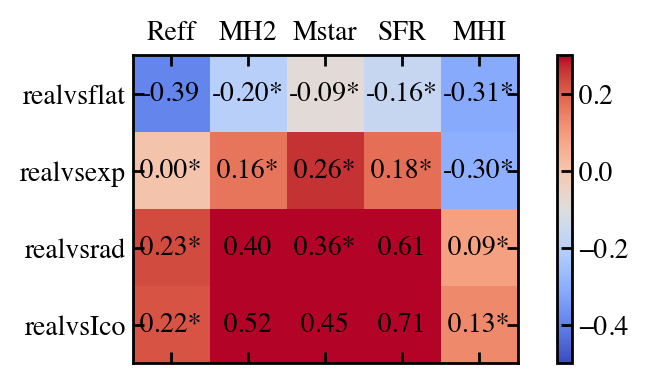

In [134]:
# construct the correlation matrix

plt.rcParams['text.usetex'] = False

col1 = ['realvsflat', 'realvsexp', 'realvsrad', 'realvsIco']

df1 = twopt_fid_amp[col1].to_pandas(); df1.astype('float')
df2 = source_for_twopt[columns].to_pandas(); df2.astype('float')

correlation_matrix = pd.DataFrame(index=df1.columns, columns=df2.columns)

# Step 4: Compute the correlation for each pair of columns
for col1 in df1.columns:
    for col2 in df2.columns:
        correlation_matrix.loc[col1, col2] = df1[col1].corr(df2[col2], method='spearman')

corr_matrix, pvals_matrix = corr_with_pvalues(df1, df2)
    
corr_matrix = corr_matrix.astype('float')

fig, ax = plt.subplots(figsize=(5, 2))
cax = ax.matshow(corr_matrix, cmap='coolwarm', vmax=0.3, vmin=-0.5)
fig.colorbar(cax)

# Set axis labels
ax.set_xticks(np.arange(len(df2.columns)))
ax.set_yticks(np.arange(len(df1.columns)))
ax.set_xticklabels(['Reff', 'MH2', "Mstar", 'SFR', "MHI"])
ax.set_yticklabels(df1.columns)

for (i, j), val in np.ndenumerate(corr_matrix.astype(float).values):
    if np.array(pvals_matrix)[i][j] > 0.05:
        ax.text(j, i, f'{val:.2f}'+'*', ha='center', va='center', color='black', fontsize=10)
    else:
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', color='black', fontsize=10)

plt.savefig('../plots/twopt_correlation_with_globalpropt.png', bbox_inches='tight')



## Try the 150 pc low resolution for one galaxy

See for each single galaxy, how the shape differ between low and high sensitivity data. What we see is:
1. For most of galaxies, the shape show dramatic difference between low and high sensitivity. Generally by a factor of 2. Most extreme cases are NGC 3351.

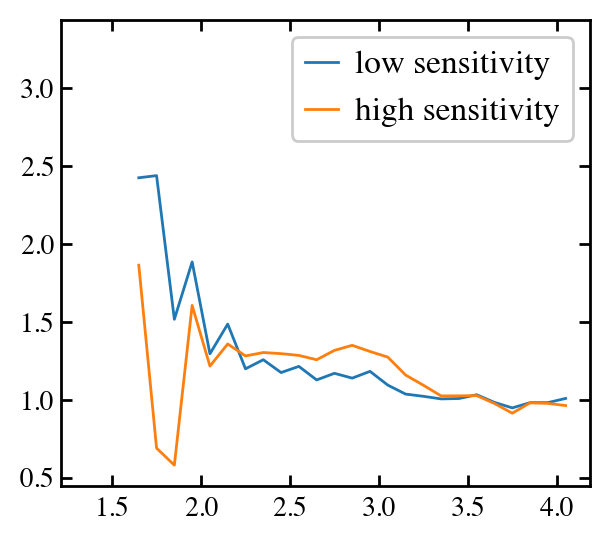

In [135]:
source_array = get_source_list('../corr_lo_150pc_results')

this_source = 'ngc3627'
filename = '../corr_lo_150pc_results/'+this_source+'_realvsIco.fits'
filename = '../corr_results_lo_150pc_strict/'+this_source+'_realvsIco.fits'
realvsIco_lo = Table.read(filename)

fig = plt.figure()
this_x = np.log10(realvsIco_lo['xgeo'])
this_y = (realvsIco_lo['twopt'])
plt.plot(this_x, this_y, label='low sensitivity')
this_x = np.log10(corr_dict[this_source]['realvsIco']['xgeo'])
this_y = corr_dict[this_source]['realvsIco']['twopt']
plt.plot(this_x, this_y, label='high sensitivity')
plt.legend()

## Try galaxies with center masked and number density

In [136]:
corr_dict_no_center = {}

source_no_center = get_source_list('../corr_results_deproj_nocenter')

for this_source in source_no_center:
    realvsflat_file = '../corr_results_deproj_nocenter/'+this_source+'_realvsflat.fits'
    realvsflat_file = Table.read(realvsflat_file)
    realvsexp_file = '../corr_results_deproj_nocenter/'+this_source+'_realvsexp.fits'
    realvsexp_file = Table.read(realvsexp_file)
    realvsrad_file = '../corr_results_deproj_nocenter/'+this_source+'_realvsrad.fits'
    realvsrad_tab = Table.read(realvsrad_file)
    realvsIco_file = '../corr_results_deproj_nocenter/'+this_source+'_realvsIco.fits'
    realvsIco_tab = Table.read(realvsIco_file)
    corr_dict_no_center[this_source] = {
        'realvsflat':realvsflat_tab,
        'realvsexp':realvsexp_tab,
        'realvsrad':realvsrad_tab, 
        'realvsIco':realvsIco_tab, 
    }
    
corr_dict_ndens = {}


for this_source in source_list:
    realvsflat_file = '../corr_results_deproj_ndens/'+this_source+'_realvsflat.fits'
    realvsflat_file = Table.read(realvsflat_file)
    realvsexp_file = '../corr_results_deproj_ndens/'+this_source+'_realvsexp.fits'
    realvsexp_file = Table.read(realvsexp_file)
    realvsrad_file = '../corr_results_deproj_ndens/'+this_source+'_realvsrad.fits'
    realvsrad_tab = Table.read(realvsrad_file)
    realvsIco_file = '../corr_results_deproj_ndens/'+this_source+'_realvsIco.fits'
    realvsIco_tab = Table.read(realvsIco_file)
    realvsngmc_file = '../corr_results_deproj_ndens/'+this_source+'_realvsngmc.fits'
    realvsngmc_tab = Table.read(realvsngmc_file)
    
    corr_dict_ndens[this_source] = {
        'realvsflat':realvsflat_tab,
        'realvsexp':realvsexp_tab,
        'realvsrad':realvsrad_tab, 
        'realvsIco':realvsIco_tab,
        'realvsngmc':realvsngmc_tab,  
    }
    


/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


Text(0.1, 0.8, 'ngc1097')

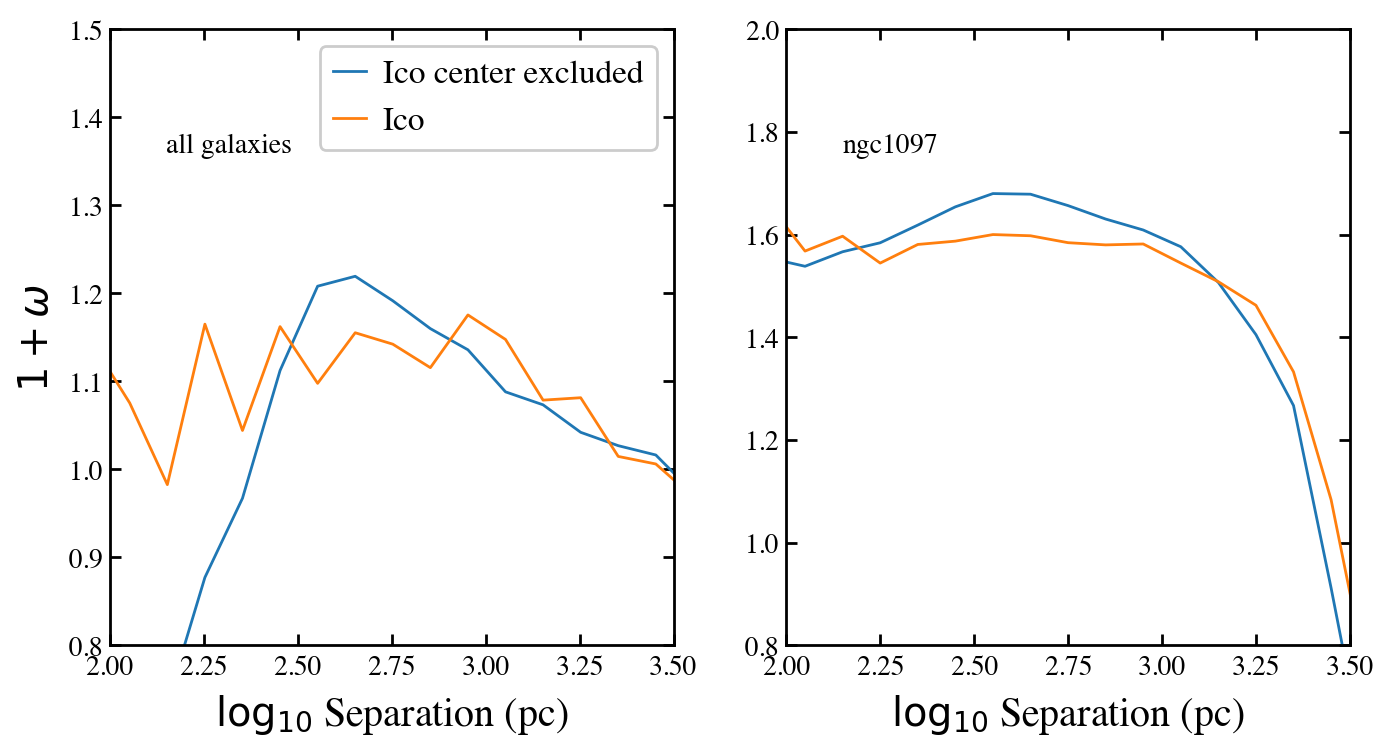

In [137]:
fig = plt.figure(figsize=(8,4))
ax = plt.subplot(121)
ax.set_xlabel(r'$\log_{10}$ Separation (pc)'); ax.set_ylabel(r'$1+\omega$')
ax.set_ylim(0.8, 1.5); ax.set_xlim(left=2, right=3.5)
bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_no_center, source_no_center, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, label='Ico center excluded')
bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict, source_no_center, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, label='Ico')
plt.legend()
ax.annotate('all galaxies', (0.1, 0.8), xycoords='axes fraction', fontsize=10)

# try one galaxy
this_source = 'ngc1097'
ax = plt.subplot(122)
ax.set_xlabel(r'$\log_{10}$ Separation (pc)')
ax.set_ylim(0.8, 2); ax.set_xlim(left=2, right=3.5)
this_x = np.log10(corr_dict_no_center[this_source]['realvsIco']['xgeo'])
this_y = corr_dict_ndens[this_source]['realvsIco']['twopt']
plt.plot(this_x, this_y, label='Ico center exluded')
this_y = corr_dict[this_source]['realvsIco']['twopt']
plt.plot(this_x, this_y, label='Ico')
ax.annotate(this_source, (0.1, 0.8), xycoords='axes fraction', fontsize=10)

/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))


/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


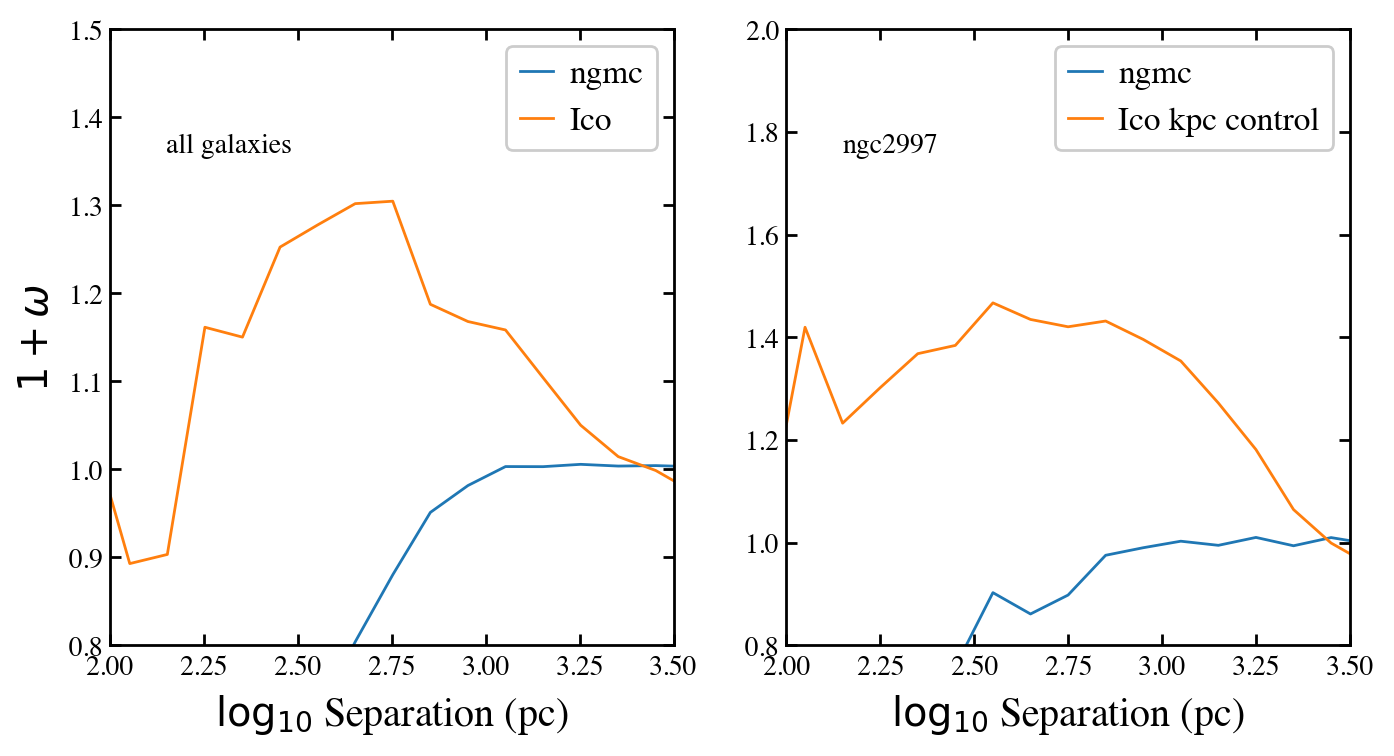

In [138]:

fig = plt.figure(figsize=(8,4))
ax = plt.subplot(121)
ax.set_xlabel(r'$\log_{10}$ Separation (pc)'); ax.set_ylabel(r'$1+\omega$')
ax.set_ylim(0.8, 1.5); ax.set_xlim(left=2, right=3.5)
bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_ndens, source_bin, tpcf_tag='realvsngmc')
plt.plot(np.log10(bins_xgeo), corr_agg_50, label='ngmc')
bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_ndens, source_bin, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, label='Ico')
plt.legend()
ax.annotate('all galaxies', (0.1, 0.8), xycoords='axes fraction', fontsize=10)

# Try for one galaxy NGC 3627
this_source = 'ngc2997'
ax = plt.subplot(122)
ax.set_xlabel(r'$\log_{10}$ Separation (pc)')
ax.set_ylim(0.8, 2); ax.set_xlim(left=2, right=3.5)
this_x = np.log10(corr_dict_ndens[this_source]['realvsngmc']['xgeo'])
this_y = corr_dict_ndens[this_source]['realvsngmc']['twopt']
plt.plot(this_x, this_y, label='ngmc')
this_y = corr_dict[this_source]['realvsIco']['twopt']
plt.plot(this_x, this_y, label='Ico kpc control')
ax.annotate(this_source, (0.1, 0.8), xycoords='axes fraction', fontsize=10)
plt.legend()

## Try the 150 pc as control

/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/3191599577.py:54: RuntimeWarning: invalid value encountered in double_scalars
  1.253 * (np.nanpercentile(vec,84) - np.nanpercentile(vec,50))/np.sqrt(n_fin)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/nanfunctions.py:1559: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff

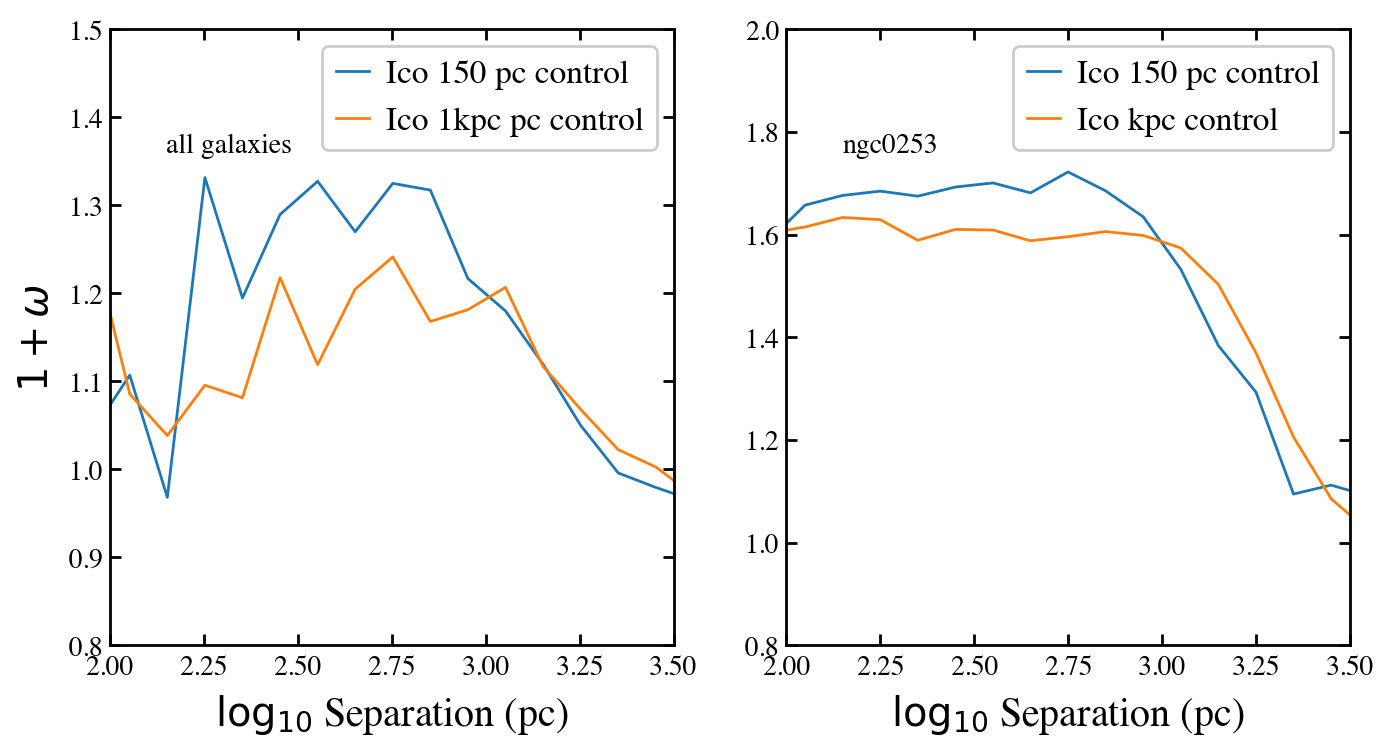

In [139]:
%matplotlib inline
corr_dict_control_test = {}

for this_source in source_list:
    realvsIco_file = '../corr_results_control_150pc/'+this_source+'_realvsIco.fits'
    realvsIco_tab = Table.read(realvsIco_file)
    corr_dict_control_test[this_source] = {
        'realvsIco':realvsIco_tab, 
    }
    
fig = plt.figure(figsize=(8,4))
ax = plt.subplot(121)
ax.set_xlabel(r'$\log_{10}$ Separation (pc)'); ax.set_ylabel(r'$1+\omega$')
ax.set_ylim(0.8, 1.5); ax.set_xlim(left=2, right=3.5)
bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_control_test, source_bin, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, label='Ico 150 pc control')
bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict, source_bin, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, label='Ico 1kpc pc control')
plt.legend()
ax.annotate('all galaxies', (0.1, 0.8), xycoords='axes fraction', fontsize=10)

# Try for one galaxy NGC 3627
this_source = 'ngc0253'
ax = plt.subplot(122)
ax.set_xlabel(r'$\log_{10}$ Separation (pc)')
ax.set_ylim(0.8, 2); ax.set_xlim(left=2, right=3.5)
this_x = np.log10(corr_dict_control_test[this_source]['realvsIco']['xgeo'])
this_y = corr_dict_control_test[this_source]['realvsIco']['twopt']
plt.plot(this_x, this_y, label='Ico 150 pc control')
this_y = corr_dict[this_source]['realvsIco']['twopt']
plt.plot(this_x, this_y, label='Ico kpc control')
ax.annotate(this_source, (0.1, 0.8), xycoords='axes fraction', fontsize=10)
plt.legend()

plt.savefig('../plots/control_test.png', bbox_inches='tight')

Overplot the monte carlo simulation results

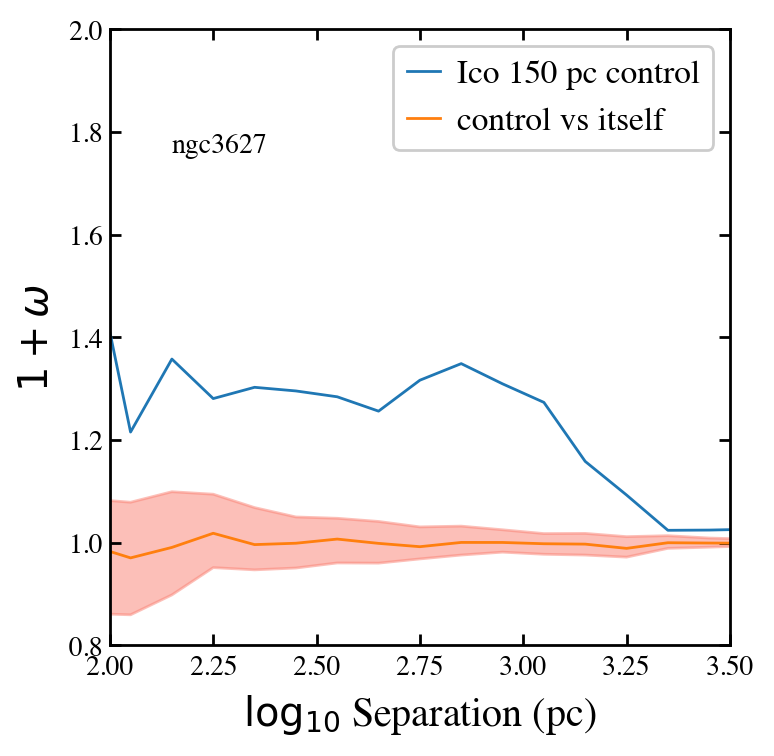

In [140]:
this_source = 'ngc3627'
fig = plt.figure(figsize=(4,4))
ax = plt.subplot(111)
ax.set_xlabel(r'$\log_{10}$ Separation (pc)'); ax.set_ylabel(r'$1+\omega$')
ax.set_ylim(0.8, 2); ax.set_xlim(left=2, right=3.5)
this_x = np.log10(corr_dict_control_test[this_source]['realvsIco']['xgeo'])
this_y = corr_dict[this_source]['realvsIco']['twopt']
plt.plot(this_x, this_y, label='Ico 150 pc control')
this_y = corr_dict_control_test[this_source]['realvsIco']['monte50']
this_16th = corr_dict_control_test[this_source]['realvsIco']['monte16']
this_84th = corr_dict_control_test[this_source]['realvsIco']['monte84']
plt.plot(this_x, this_y, label='control vs itself')
ax.annotate(this_source, (0.1, 0.8), xycoords='axes fraction', fontsize=10)
ax.fill_between(this_x, this_16th, this_84th, color='salmon', alpha=0.5)
plt.legend()
plt.savefig('../plots/ngc3627_monte_sim.png', bbox_inches='tight')

## Try the 60 pc resolution tpcf

In [141]:
source_array = get_source_list('../corr_60pc_hi_results')
# source_array = np.delete(source_array, 0)

# get the number of clouds for each source
for this_source in source_array:
    cloud_cat = Table.read('../homogen_hi_60pc_props/'+this_source+'_12m+7m+tp_co21_60pc_83mK_props.fits')
    print('number of clouds for ', this_source, ': ', len(cloud_cat))

corr_dict_60pc_hi = {}
for this_source in source_array:
    realvsIco_file = '../corr_60pc_hi_results/'+this_source+'_60pc_realvsIco.fits'
    realvsIco_tab = Table.read(realvsIco_file)
    corr_dict_60pc_hi[this_source] = {
        'realvsIco':realvsIco_tab,
    }
    
corr_dict_150pc_orig = {}
for this_source in source_array:
    realvsIco_file = '../corr_results/'+this_source+'_realvsIco.fits'
    realvsIco_tab = Table.read(realvsIco_file)
    corr_dict_150pc_orig[this_source] = {
        'realvsIco':realvsIco_tab,
    }

number of clouds for  ngc3489 :  31


number of clouds for  ngc3621 :  660
number of clouds for  ngc4459 :  60
number of clouds for  ngc4596 :  13
number of clouds for  ngc4826 :  68
number of clouds for  ngc5068 :  140
number of clouds for  ngc5236 :  1517


/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))


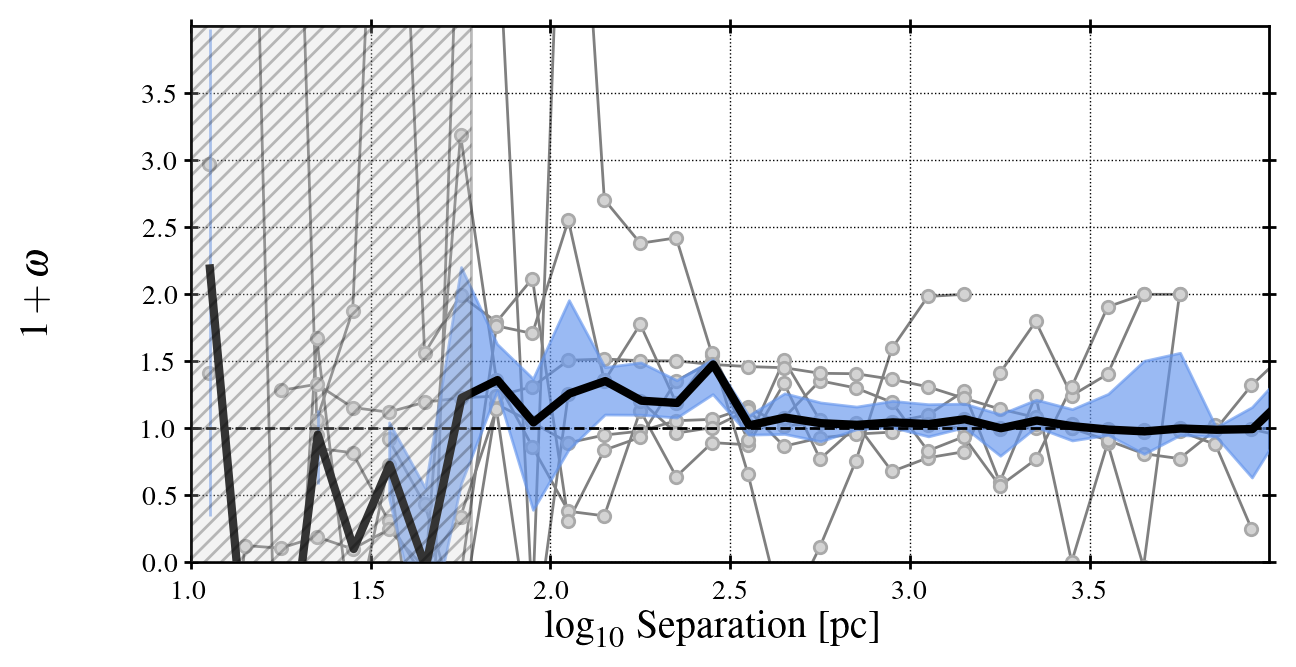

In [142]:
png_name = '../plots/twopt_onepanel_Ico_60pc.png'

npanels = 1
ncol = 1
nrow = 1
ticklength = 5

xmin = +1.0
xmax = +4.0
ymin = 0.0
ymax = 4.0
xticks = np.arange(xmin,xmax,0.5)
yticks = np.arange(ymin,ymax,0.5)

mpl_setup('paper-1/1', aspect=3./6., fs=12)

fig, axes = plt.subplots(
    nrow, ncol, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10}$ Separation [pc]'
ylabel = r'$1 + \omega$'

fig.text(0.015, 0.5, ylabel, va='center', ha='center', rotation='vertical', fontsize='large')
fig.text(0.5, 0.015, xlabel, va='center', ha='center', rotation='horizontal', fontsize='large')

rows_done = 0
counter = 0

beam_scale = np.log10(60.)

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
axes.set_xticks(xticks)
axes.set_yticks(yticks)
axes.tick_params(direction='inout', length=ticklength)

axes.grid(True, linestyle='dotted',linewidth=0.5,color='black')

plot_main_legend = True
plot_bbox = True
plot_aggregate = True

this_label = r'\textbf{Data vs. Ico, 60pc}'
this_tab_tag = 'realvsIco'

agg_16 = realvsIco_16
agg_50 = realvsIco_50
agg_84 = realvsIco_84
agg_lo = realvsIco_errlo
agg_hi = realvsIco_errhi

axes.plot([xmin,xmax],[1.,1.],color='black',linestyle='dashed',zorder=7)

for this_source in corr_dict_60pc_hi.keys():

    this_tab = corr_dict_60pc_hi[this_source][this_tab_tag]

    this_x = np.log10(this_tab['xgeo'])
    this_y = (this_tab['twopt'])

    axes.scatter(this_x,this_y,marker='o',s=20,
                      edgecolor='darkgray',facecolor='lightgray',
                      zorder=2)

    axes.plot(this_x,this_y,zorder=1,linestyle='solid',color='gray')

axes.fill_betweenx(np.array([ymin,ymax]),xmin+np.array([0.,0.]),
                        (beam_scale)+np.array([0.,0.]),
                        hatch='////',facecolor='lightgray',alpha=0.25,
                        zorder=8,edgecolor=r'black',label=r'Beam')

bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_60pc_hi, source_array, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, color='black', zorder=5, linewidth=3)
plt.fill_between(np.log10(bins_xgeo), (corr_agg_50-corr_agg_errlo), (corr_agg_50+corr_agg_errhi), color='cornflowerblue', zorder=5, alpha=0.65)

    # axes.fill_between(np.log10(agg_x),(agg_yerrlo),(agg_yerrhi),
    #                        color='cornflowerblue',zorder=4,alpha=0.65, label=r'Unc. on med.')

    # axes.plot(np.log10(agg_x),(agg_50),linestyle='solid',color='black',
    #                zorder=5, linewidth=3, label=r'Median')

# if plot_aggregate:
#     agg_x = bins_xgeo            
#     axes.fill_between(np.log10(agg_x),(agg_16),(agg_84),
#                            color='salmon',zorder=3,alpha=0.5, label=r'16-84\% range')
#     agg_yerrlo = agg_50 - agg_lo
#     agg_yerrhi = agg_50 + agg_hi
#     axes.fill_between(np.log10(agg_x),(agg_yerrlo),(agg_yerrhi),
#                            color='cornflowerblue',zorder=4,alpha=0.65, label=r'Unc. on med.')

#     axes.plot(np.log10(agg_x),(agg_50),linestyle='solid',color='black',
#                    zorder=5, linewidth=3, label=r'Median')

# bbox_props = dict(boxstyle="round", fc="lightgray", ec='black',alpha=0.9)
# axes.text(0.975, 0.01, this_label,
#         ha='right', va='bottom',
#         transform=ax.transAxes,
#         size='medium', bbox=bbox_props,
#         zorder=10)

# if plot_main_legend:
#     axes.legend(fancybox=True, framealpha=0.95, loc=(0.645,0.65), #loc='upper right', 
#         ncol=1, fontsize=10, handlelength=2)    

#fig.tight_layout()
plt.savefig('../plots/twopt_60pc.png', bbox_inches='tight')

/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4489: RuntimeWarning: invalid value encountered in subtract
  subtract(b, diff_b_a * (1 - t), out=lerp_interpolation, where=t >= 0.5)


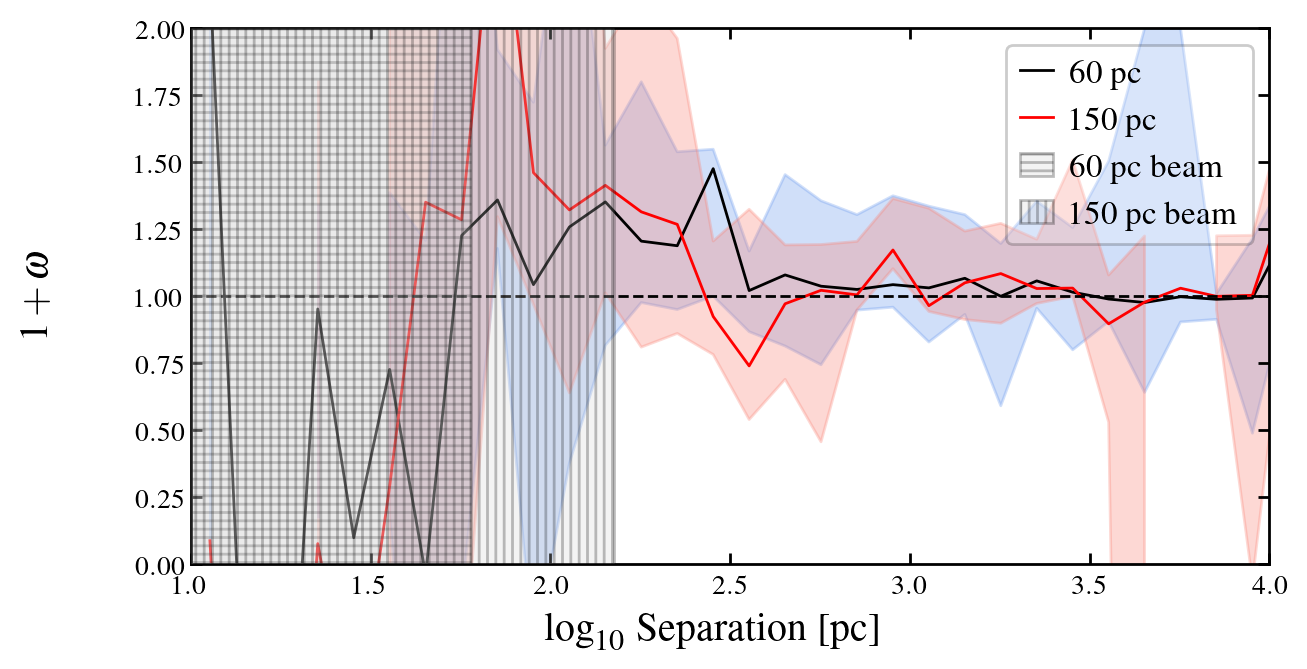

In [143]:
fig = plt.figure()
xlabel = r'$\log_{10}$ Separation [pc]'
ylabel = r'$1 + \omega$'

fig.text(0.015, 0.5, ylabel, va='center', ha='center', rotation='vertical', fontsize='large')
fig.text(0.5, 0.015, xlabel, va='center', ha='center', rotation='horizontal', fontsize='large')

axes = plt.subplot(111)
ymin = 0; ymax = 2; xmin = 1; xmax=4
axes.set_ylim(0,2); axes.set_xlim(1, 4)
bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_60pc_hi, source_array, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, color='black', label='60 pc')
plt.fill_between(np.log10(bins_xgeo), (corr_agg_16), (corr_agg_84), color='cornflowerblue', alpha=0.3)

bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_150pc_orig, source_array, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, color='red', label='150 pc')
plt.fill_between(np.log10(bins_xgeo), (corr_agg_16), (corr_agg_84), color='salmon', alpha=0.3)

axes.fill_betweenx(np.array([ymin,ymax]),xmin+np.array([0.,0.]),
                        (np.log10(60))+np.array([0.,0.]),
                        hatch='----',facecolor='lightgray',alpha=0.25,
                        zorder=8,edgecolor=r'black',label=r'60 pc beam')
axes.fill_betweenx(np.array([ymin,ymax]),xmin+np.array([0.,0.]),
                        (np.log10(150))+np.array([0.,0.]),
                        hatch='||||',facecolor='lightgray',alpha=0.25,
                        zorder=8,edgecolor=r'black',label=r'150 pc beam')
axes.axhline(1, ls='dashed', color='black')
plt.legend()
plt.savefig('../plots/twopt_60pc_150pc_comparison.png', bbox_inches='tight', dpi=300)


## Test the auto-correlation only in spiral arms

In [144]:
corr_dir = '../corr_results_hi_150pc_arm/'
source_array = get_source_list(corr_dir)

corr_dict_arm = {}
for this_source in source_array:
    # realvsflat_file = corr_dir+this_source+'_realvsflat.fits'
    # realvsexp_file = corr_dir+this_source+'_realvsexp.fits'
    realvsrad_file = corr_dir+this_source+'_realvsrad.fits'
    realvsIco_file = corr_dir+this_source+'_realvsIco.fits'
    realvsIco_tab = Table.read(realvsIco_file)
    realvsrad_tab = Table.read(realvsrad_file)
    corr_dict_arm[this_source] = {
        'realvsrad':realvsrad_tab,
        'realvsIco':realvsIco_tab,
    }

corr_dir = '../corr_results/'
corr_dict_arm2 = {}
for this_source in source_array:
    # realvsflat_file = corr_dir+this_source+'_realvsflat.fits'
    # realvsexp_file = corr_dir+this_source+'_realvsexp.fits'
    realvsrad_file = corr_dir+this_source+'_realvsrad.fits'
    realvsIco_file = corr_dir+this_source+'_realvsIco.fits'
    realvsIco_tab = Table.read(realvsIco_file)
    realvsrad_tab = Table.read(realvsrad_file)
    corr_dict_arm2[this_source] = {
        'realvsrad':realvsrad_tab,
        'realvsIco':realvsIco_tab,
    }

/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))


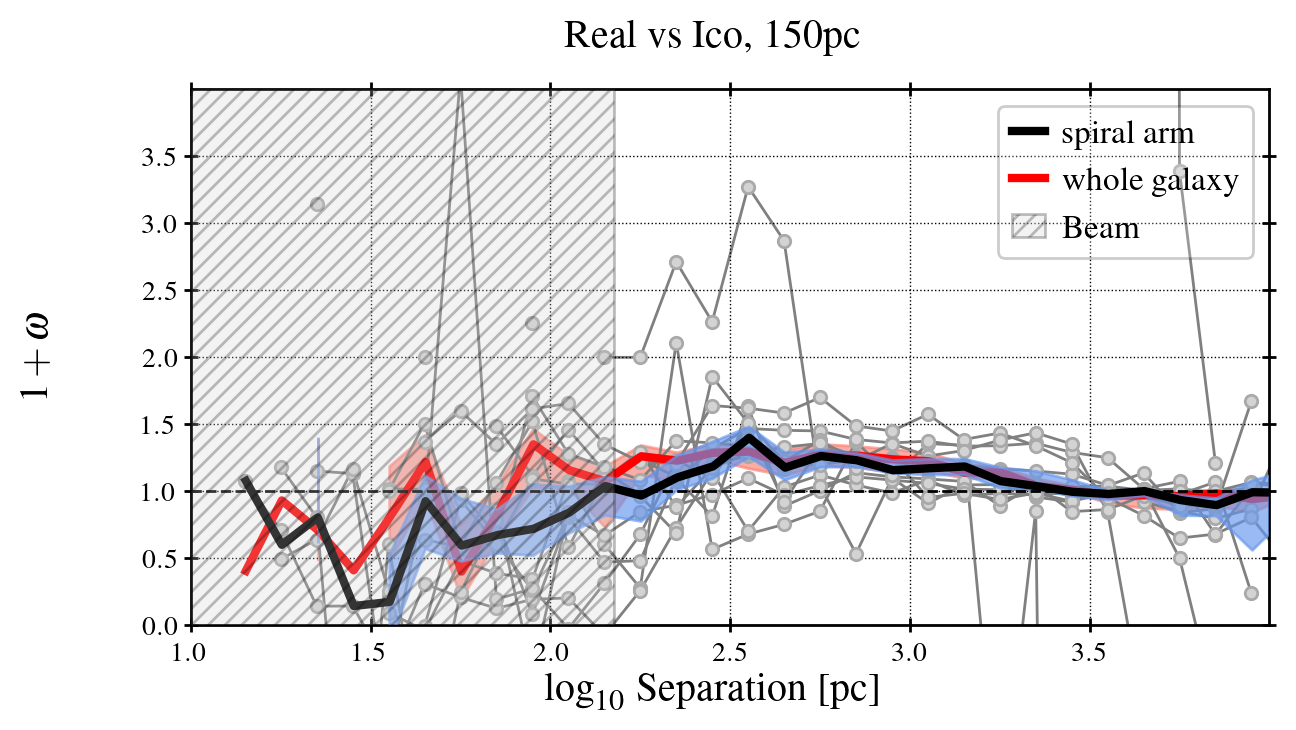

In [145]:
png_name = '../plots/twopt_onepanel_Ico_arms.png'

npanels = 1
ncol = 1
nrow = 1
ticklength = 5

xmin = +1.0
xmax = +4.0
ymin = 0.0
ymax = 4.0
xticks = np.arange(xmin,xmax,0.5)
yticks = np.arange(ymin,ymax,0.5)

mpl_setup('paper-1/1', aspect=3./6., fs=12)

fig, axes = plt.subplots(
    nrow, ncol, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10}$ Separation [pc]'
ylabel = r'$1 + \omega$'

fig.text(0.015, 0.5, ylabel, va='center', ha='center', rotation='vertical', fontsize='large')
fig.text(0.5, 0.015, xlabel, va='center', ha='center', rotation='horizontal', fontsize='large')

rows_done = 0
counter = 0

beam_scale = np.log10(150.)

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
axes.set_xticks(xticks)
axes.set_yticks(yticks)
axes.tick_params(direction='inout', length=ticklength)

axes.grid(True, linestyle='dotted',linewidth=0.5,color='black')

plot_main_legend = True
plot_bbox = True
plot_aggregate = True

this_label = r'\textbf{Data vs. Ico, 60pc}'
this_tab_tag = 'realvsIco'

agg_16 = realvsIco_16
agg_50 = realvsIco_50
agg_84 = realvsIco_84
agg_lo = realvsIco_errlo
agg_hi = realvsIco_errhi

axes.plot([xmin,xmax],[1.,1.],color='black',linestyle='dashed',zorder=7)

for this_source in corr_dict_arm.keys():

    this_tab = corr_dict_arm[this_source][this_tab_tag]

    this_x = np.log10(this_tab['xgeo'])
    this_y = (this_tab['twopt'])

    axes.scatter(this_x,this_y,marker='o',s=20,
                      edgecolor='darkgray',facecolor='lightgray',
                      zorder=2)

    axes.plot(this_x,this_y,zorder=1,linestyle='solid',color='gray')

axes.fill_betweenx(np.array([ymin,ymax]),xmin+np.array([0.,0.]),
                        (beam_scale)+np.array([0.,0.]),
                        hatch='////',facecolor='lightgray',alpha=0.25,
                        zorder=8,edgecolor=r'black',label=r'Beam')

bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_arm, source_array, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, color='black', zorder=5, linewidth=3, label='spiral arm')
plt.fill_between(np.log10(bins_xgeo), (corr_agg_50-corr_agg_errlo), (corr_agg_50+corr_agg_errhi), color='cornflowerblue', zorder=5, alpha=0.65)

bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_arm2, source_array, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, color='red', label='whole galaxy', linewidth=3)
plt.fill_between(np.log10(bins_xgeo), (corr_agg_50-corr_agg_errlo), (corr_agg_50+corr_agg_errhi), color='salmon', alpha=0.65)  

plt.suptitle('Real vs Ico, 150pc')
plt.legend()

plt.savefig('../plots/twopt_arms.png', bbox_inches='tight')

/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))


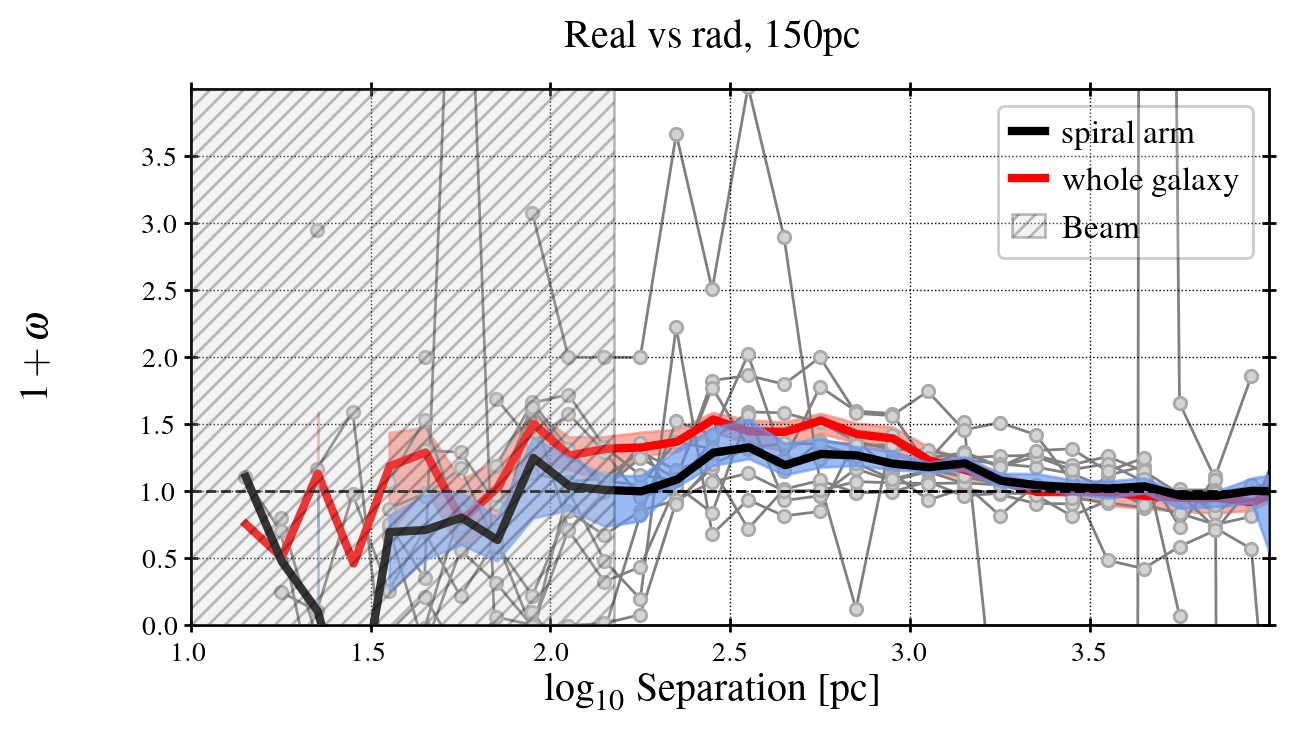

In [148]:
png_name = '../plots/twopt_onepanel_radial_arms.png'

npanels = 1
ncol = 1
nrow = 1
ticklength = 5

xmin = +1.0
xmax = +4.0
ymin = 0.0
ymax = 4.0
xticks = np.arange(xmin,xmax,0.5)
yticks = np.arange(ymin,ymax,0.5)

mpl_setup('paper-1/1', aspect=3./6., fs=12)

fig, axes = plt.subplots(
    nrow, ncol, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10}$ Separation [pc]'
ylabel = r'$1 + \omega$'

fig.text(0.015, 0.5, ylabel, va='center', ha='center', rotation='vertical', fontsize='large')
fig.text(0.5, 0.015, xlabel, va='center', ha='center', rotation='horizontal', fontsize='large')

rows_done = 0
counter = 0

beam_scale = np.log10(150.)

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
axes.set_xticks(xticks)
axes.set_yticks(yticks)
axes.tick_params(direction='inout', length=ticklength)

axes.grid(True, linestyle='dotted',linewidth=0.5,color='black')

plot_main_legend = True
plot_bbox = True
plot_aggregate = True

this_label = r'\textbf{Data vs. rad, 150pc}'
this_tab_tag = 'realvsrad'

agg_16 = realvsIco_16
agg_50 = realvsIco_50
agg_84 = realvsIco_84
agg_lo = realvsIco_errlo
agg_hi = realvsIco_errhi

axes.plot([xmin,xmax],[1.,1.],color='black',linestyle='dashed',zorder=7)

for this_source in corr_dict_arm.keys():

    this_tab = corr_dict_arm[this_source][this_tab_tag]

    this_x = np.log10(this_tab['xgeo'])
    this_y = (this_tab['twopt'])

    axes.scatter(this_x,this_y,marker='o',s=20,
                      edgecolor='darkgray',facecolor='lightgray',
                      zorder=2)

    axes.plot(this_x,this_y,zorder=1,linestyle='solid',color='gray')

axes.fill_betweenx(np.array([ymin,ymax]),xmin+np.array([0.,0.]),
                        (beam_scale)+np.array([0.,0.]),
                        hatch='////',facecolor='lightgray',alpha=0.25,
                        zorder=8,edgecolor=r'black',label=r'Beam')

bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_arm, source_array, tpcf_tag='realvsrad')
plt.plot(np.log10(bins_xgeo), corr_agg_50, color='black', zorder=5, linewidth=3, label='spiral arm')
plt.fill_between(np.log10(bins_xgeo), (corr_agg_50-corr_agg_errlo), (corr_agg_50+corr_agg_errhi), color='cornflowerblue', zorder=5, alpha=0.65)

bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_arm2, source_array, tpcf_tag='realvsrad')
plt.plot(np.log10(bins_xgeo), corr_agg_50, color='red', label='whole galaxy', linewidth=3)
plt.fill_between(np.log10(bins_xgeo), (corr_agg_50-corr_agg_errlo), (corr_agg_50+corr_agg_errhi), color='salmon', alpha=0.65)  

plt.suptitle('Real vs rad, 150pc')
plt.legend()

plt.savefig('../plots/twopt_arms_rad.png', bbox_inches='tight')

## Test auto-correlation only with brightest clouds

In [149]:
corr_dir = '../corr_results_hi_150pc_bright/'
source_array = get_source_list(corr_dir)

corr_dict_bright = {}
for this_source in source_array:
    # realvsflat_file = corr_dir+this_source+'_realvsflat.fits'
    # realvsexp_file = corr_dir+this_source+'_realvsexp.fits'
    realvsrad_file = corr_dir+this_source+'_realvsrad.fits'
    realvsIco_file = corr_dir+this_source+'_realvsIco.fits'
    realvsIco_tab = Table.read(realvsIco_file)
    realvsrad_tab = Table.read(realvsrad_file)
    corr_dict_bright[this_source] = {
        'realvsrad':realvsrad_tab,
        'realvsIco':realvsIco_tab,
    }

/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_43257/2261739951.py:74: RuntimeWarning: invalid value encountered in add
  plt.fill_between(np.log10(bins_xgeo), (corr_agg_50-corr_agg_errlo), (corr_agg_50+corr_agg_errhi), color='cornflowerblue', zorder=5, alpha=0.65)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4488: RuntimeWarning: invalid value encountered in add
  lerp_interpolation = asanyarray(add(a, diff_b_a * t, out=out))
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4486: RuntimeWarning: 

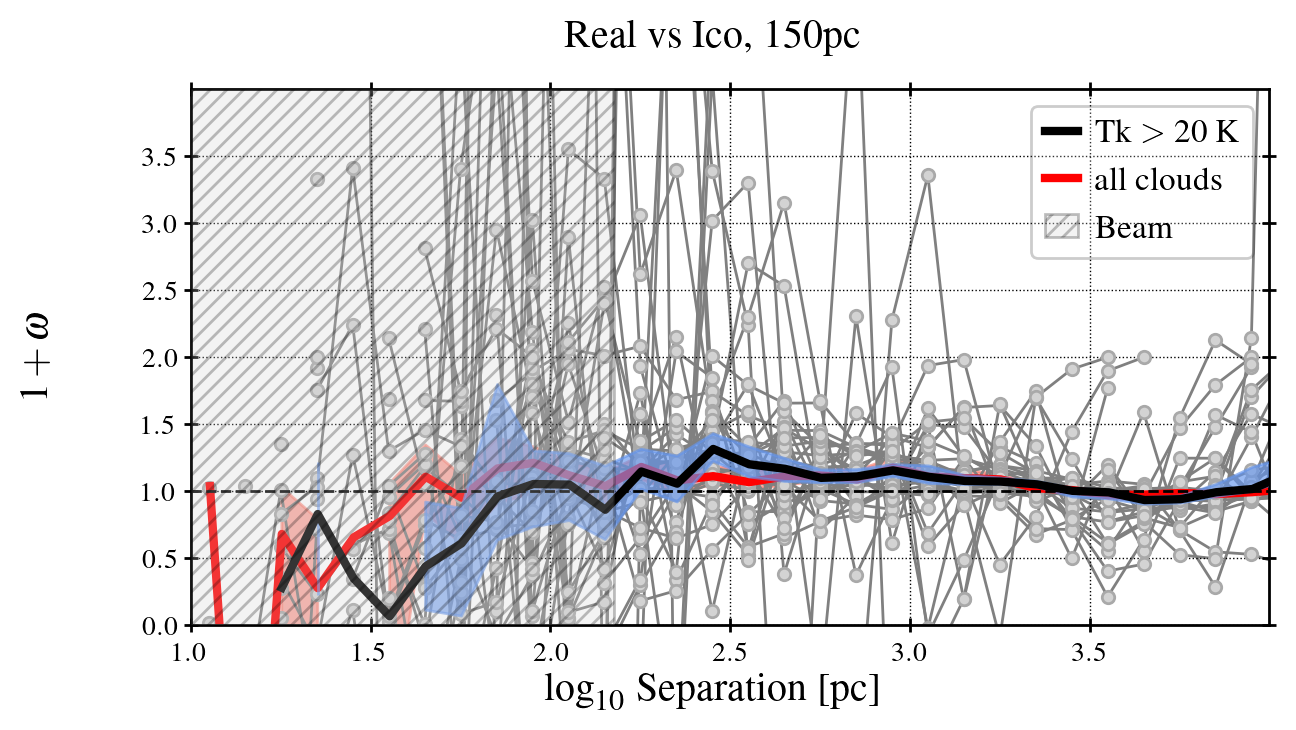

In [150]:
npanels = 1
ncol = 1
nrow = 1
ticklength = 5

xmin = +1.0
xmax = +4.0
ymin = 0.0
ymax = 4.0
xticks = np.arange(xmin,xmax,0.5)
yticks = np.arange(ymin,ymax,0.5)

mpl_setup('paper-1/1', aspect=3./6., fs=12)

fig, axes = plt.subplots(
    nrow, ncol, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10}$ Separation [pc]'
ylabel = r'$1 + \omega$'

fig.text(0.015, 0.5, ylabel, va='center', ha='center', rotation='vertical', fontsize='large')
fig.text(0.5, 0.015, xlabel, va='center', ha='center', rotation='horizontal', fontsize='large')

rows_done = 0
counter = 0

beam_scale = np.log10(150.)

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
axes.set_xticks(xticks)
axes.set_yticks(yticks)
axes.tick_params(direction='inout', length=ticklength)

axes.grid(True, linestyle='dotted',linewidth=0.5,color='black')

plot_main_legend = True
plot_bbox = True
plot_aggregate = True

this_label = r'\textbf{Data vs. Ico, 150pc}'
this_tab_tag = 'realvsIco'

agg_16 = realvsIco_16
agg_50 = realvsIco_50
agg_84 = realvsIco_84
agg_lo = realvsIco_errlo
agg_hi = realvsIco_errhi

axes.plot([xmin,xmax],[1.,1.],color='black',linestyle='dashed',zorder=7)

for this_source in corr_dict_bright.keys():

    this_tab = corr_dict_bright[this_source][this_tab_tag]

    this_x = np.log10(this_tab['xgeo'])
    this_y = (this_tab['twopt'])

    axes.scatter(this_x,this_y,marker='o',s=20,
                      edgecolor='darkgray',facecolor='lightgray',
                      zorder=2)

    axes.plot(this_x,this_y,zorder=1,linestyle='solid',color='gray')

axes.fill_betweenx(np.array([ymin,ymax]),xmin+np.array([0.,0.]),
                        (beam_scale)+np.array([0.,0.]),
                        hatch='////',facecolor='lightgray',alpha=0.25,
                        zorder=8,edgecolor=r'black',label=r'Beam')

bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict_bright, source_array, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, color='black', zorder=5, linewidth=3, label='Tk $>$ 20 K')
plt.fill_between(np.log10(bins_xgeo), (corr_agg_50-corr_agg_errlo), (corr_agg_50+corr_agg_errhi), color='cornflowerblue', zorder=5, alpha=0.65)

bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi = agregt_bins_ppac(corr_dict, source_list, tpcf_tag='realvsIco')
plt.plot(np.log10(bins_xgeo), corr_agg_50, color='red', label='all clouds', linewidth=3)
plt.fill_between(np.log10(bins_xgeo), (corr_agg_50-corr_agg_errlo), (corr_agg_50+corr_agg_errhi), color='salmon', alpha=0.65)  

plt.suptitle('Real vs Ico, 150pc')
plt.legend()

plt.savefig('../plots/twopt_bright.png', bbox_inches='tight')